# 32i quantification v2 — SlideTags

Rewrite of `quantify_32i_SlideTags.ipynb`. Same data, same BAMs, same donors; corrected metrics and new analyses.

**Corrections w.r.t. v1**

| v1 | v2 | why |
|---|---|---|
| "post" = genomic span exon33 → TAF1 end (incl. introns 33-37, labelled "exonic") | `post_span` kept only for the v1-compatible metric; new `post_exonic` = reads with an aligned block on exons 33 → last exon (from the GTF) | the old window mixed intronic and exonic reads |
| intron 32 downstream of the SVA never counted | `postSVA_intron` window | gives a within-intron "read-through" metric |
| no control for a global shift of intronic reads | upstream TAF1 introns (`ctrl_intron`) as negative control + `pct_intronic` as covariate | separates a 32i-specific effect from "more intronic reads everywhere" |
| antisense ratio = pre_as / (pre_as + post_as), post_as ≈ strand-leak noise | antisense intron reads normalised to **sense** exonic TAF1 reads, and per 10k UMIs | stable denominator |
| no minimum counts | ratios set to NaN if num + other < `MIN_DENOM` | removes ratios built on a handful of UMIs |
| "All cells" = UMIs pooled across cell types | dropped; replaced by composition-standardised mean of cell-type ratios | XDP has neuron loss → pooled ratio is confounded by composition |
| raw-UMI tests (depend on n cells) | per-10k-UMI abundances (decomposition: does pre go up or does TAF1 3′ go down?) | depth/cell-number independent |
| TAF1 counts (include intronic reads = the pre window itself) correlated with the ratio | TAF1 3′ output = `post_exonic` sense per 10k UMIs, only correlated with metrics that do not contain it | removes circularity |
| Mann-Whitney on ratios only | quasi-binomial GLM on counts (± `pct_intronic`) + **exact donor-label permutation p** + MWU; BH-FDR | uses counts, effect sizes with CI, valid p with 4 vs 7 donors |
| Wilcoxon dead vs healthy (n=5 → min p = 0.0625) | quasi-binomial GLM with donor fixed effect + Wilcoxon | paired, uses counts |
| per-cell ratios in spatial plots (0/1/NaN) | kNN-smoothed counts within section and cell class; 32i vs signed distance to the dead-region border | readable spatial signal |
| `fetch` with 1-based coords, overlap off-by-one | 0-based fetch, exact overlap | minor |
| `TAF1_EXON32_INTRON32_JUNCTION_W` unused | unspliced exon32│intron32 junction reads vs spliced exon32→33 (intron retention index) | direct IR evidence |

**New analyses**: per-library reproducibility + batch/run/Sorted, sensitivity (Sorted, sample_09), ambient (non-cell barcodes), coverage profile along intron 32 by strand, cryptic splice sites in intron 32, soft-clips at the SVA insertion point (genotype check, hexamer/SVA k-mers), poly(A)-tail soft-clips (polyadenylation sites of the 32i transcript), donor sex check, optional NucSeq replication.

Requires `samtools` + `gcloud` (as v1), `pysam`, `h5py`, `anndata`, `scipy`, `seaborn`. No statsmodels needed (GLM implemented below).

In [1]:
import gzip, re, json, hashlib, itertools, subprocess, warnings
from math import comb
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import h5py
import pysam
import matplotlib.pyplot as plt
import seaborn as sns
from anndata.io import read_elem
from scipy import stats
from scipy.spatial import cKDTree

sns.set_theme(style="ticks", context="notebook")
pd.set_option("display.max_columns", 60)

# Config
Everything you may want to change is here. Coordinates are **hg38, 1-based inclusive** (as in IGV), same as v1.

In [2]:
# ---------------------------------------------------------------- paths
ADATA_PATH    = "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad"
LIB_META_PATH = "/home/gdallagl/myworkdir/XDP/utils/SlideTags_XDP_metadata/XDP Slidetags - CellBender Terra table - cb.csv"
BAM_LOCAL_DIR = "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/SlideTags_single_libraries"  # {sample}/{bcl}/{RNAindex}/bam
# GTF of the Cell Ranger reference used to make the BAMs (refdata-gex-GRCh38-*/genes/genes.gtf or .gtf.gz)
GTF_PATH       = "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/genome_fasta/refdata-gex-GRCh38-2024-A/genes/genes.gtf.gz"   # <-- TODO
TX_ID_OVERRIDE = None   # force a TAF1 transcript id; None = auto (transcript that has v1 exon32 end + exon33 start)

OUT_DIR   = Path("/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/32i_v2")
CACHE_DIR = OUT_DIR / "per_library_cache"
for p in (OUT_DIR, CACHE_DIR):
    p.mkdir(parents=True, exist_ok=True)

# optional inputs (set to None to skip the corresponding section)
V1_PER_DONOR_CSV     = Path("/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/32i/32i_per_donor_SlideTags_excl_SCF-18-006.csv")
NUCSEQ_PER_DONOR_CSV = None   # per donor x cell type csv from the NucSeq notebook (needs donor_id, ct_for_deg, pileup_metric_sense)
NUCSEQ_CT_MAP        = {}     # NucSeq cell type name -> SlideTags name, if they differ
SVA_FASTA            = None   # fasta of the XDP SVA, for k-mer confirmation of soft-clipped reads at the insertion point

DATASET = "SlideTags"
# donors removed from the ANALYSES (not from the quantification); sample_09 = paired-end run
EXCLUDE_DONORS = ["SCF-18-006"]
ANALYSIS_NAME = DATASET + ("_excl_" + "_".join(EXCLUDE_DONORS) if EXCLUDE_DONORS else "")

# ---------------------------------------------------------------- BAM subset
# new file name: v2 keeps ALL barcodes (needed for the ambient estimate) and a wider region -> v1 subsets untouched
SUBSET_BAM_NAME = "taf1_subset_allCB_v2.bam"
OVERWRITE_BAM = False   # re-download the subset even if it exists
REUSE_CACHE   = True    # reuse per-library counting results (cache key includes all counting parameters)
MIN_MAPQ = 30

# ---------------------------------------------------------------- coordinates (same as v1)
EXON32_START, EXON32_END     = 71424154, 71424238
INTRON32_START, INTRON32_END = 71424239, 71454169
EXON33_START, EXON33_END     = 71454170, 71454237
TAF1_END_V1    = 71466005   # end of the v1 "post" window, only used by the v1-compatible metric
SVA_START_BP   = 71440512   # published SVA insertion point
SVA_BUFFER     = 0          # bp excluded on each side of the insertion point (0 = same pre window as v1)
N_CTRL_INTRONS = 5          # TAF1 introns directly upstream of intron 32 used as negative control

# ---------------------------------------------------------------- read-level parameters
MIN_ANCHOR = 5                         # bp on each side for an unspliced exon32|intron32 junction read
MIN_CLIP   = 10                        # min soft-clip length for an SVA-junction clip
CLIP_TOL   = 20                        # bp around SVA_START_BP (target-site duplication / alignment ambiguity)
POLYA_MIN_LEN, POLYA_MIN_FRAC = 8, 0.8 # soft-clipped poly(A) tail -> polyadenylation site
PROFILE_BIN = 250                      # bp, coverage profile bin

# ---------------------------------------------------------------- analysis parameters
MIN_DENOM        = 30    # min UMIs (num + other) for a pseudobulk ratio, else NaN
MIN_DENOM_SPARSE = 10    # same, for junction / splice metrics
MIN_CELLS_REGION = 20
KNN_SPATIAL      = 30    # neighbours (same section, same cell class) for spatial smoothing
N_DIST_BINS_NEG, N_DIST_BINS_POS = 3, 5   # distance-to-dead-border bins (inside dead / healthy side)
COVARIATE_ADJUST = ("pct_intronic",)     # covariates in the adjusted GLM (keep it to 1 with 11 donors)
MAX_SECTIONS_PLOT = 6

CORE_CT = ["Matrix", "Patch", "eMSN_D1D2", "eMSN_NUDAP", "non-MSN", "Oligo", "OPC", "Astro", "Microglia"]
CT_CLASS = {"Matrix": "Neuron", "Patch": "Neuron", "eMSN_D1D2": "Neuron", "eMSN_NUDAP": "Neuron",
            "eMSN_StrioMat": "Neuron", "non-MSN": "Neuron",
            "Oligo": "Glia", "OPC": "Glia", "Astro": "Glia", "Microglia": "Glia"}
CLASSES = ["Neuron", "Glia"]

CONDITION_COLORS = {"Control": "#2a78d6", "XDP": "#eb6834"}
REGION_COLORS    = {"healthy": "#2a78d6", "dead": "#c0392b"}
STRAND_LABEL     = {"s": "sense", "as": "antisense"}

# TAF1 annotation
The transcript is taken from the GTF of the reference used for the BAMs: the transcript that contains exactly the v1 exon 32 end and exon 33 start. From it: exonic part of the "post" window (exon 33 → last exon) and the upstream control introns.

In [3]:
def load_gene_exons(gtf_path, gene_name):
    opener = gzip.open if str(gtf_path).endswith(".gz") else open
    key = f'gene_name "{gene_name}";'
    rows = []
    with opener(gtf_path, "rt") as f:
        for line in f:
            if key not in line:          # cheap filter before splitting
                continue
            p = line.rstrip("\n").split("\t")
            if len(p) < 9 or p[2] != "exon":
                continue
            tx_id = re.search(r'transcript_id "([^"]+)"', p[8]).group(1)
            rows.append((p[0], int(p[3]), int(p[4]), p[6], tx_id))
    return pd.DataFrame(rows, columns=["chrom", "start", "end", "strand", "transcript_id"])

taf1_exons_all = load_gene_exons(GTF_PATH, "TAF1")
assert len(taf1_exons_all), "TAF1 not found in the GTF"

In [4]:
# pick the transcript
has32 = set(taf1_exons_all.loc[taf1_exons_all["end"] == EXON32_END, "transcript_id"])
has33 = set(taf1_exons_all.loc[taf1_exons_all["start"] == EXON33_START, "transcript_id"])
candidates = sorted(has32 & has33)
assert candidates, "no TAF1 transcript has the v1 exon32 end + exon33 start: check genome build / coordinates"
n_exons = taf1_exons_all[taf1_exons_all["transcript_id"].isin(candidates)].groupby("transcript_id").size()
TX_ID = TX_ID_OVERRIDE or n_exons.idxmax()
print("candidate transcripts (n exons):", n_exons.to_dict(), "-> using", TX_ID)

tx = (taf1_exons_all[taf1_exons_all["transcript_id"] == TX_ID]
      .sort_values("start").reset_index(drop=True))
CHROM = tx["chrom"].iloc[0]
assert (tx["strand"] == "+").all()
K32 = int(np.flatnonzero(tx["end"].values == EXON32_END)[0])     # 0-based index of exon 32 in this transcript
assert tx["start"].iloc[K32 + 1] == EXON33_START
assert K32 >= N_CTRL_INTRONS, "not enough upstream introns for the control"
if K32 + 1 != 32:
    print(f"note: exon 32 (RefSeq numbering) is exon {K32 + 1} in {TX_ID}")

DOWNSTREAM_EXONS = list(zip(tx["start"].iloc[K32 + 1:], tx["end"].iloc[K32 + 1:]))
CTRL_INTRONS = [(int(tx["end"].iloc[i]) + 1, int(tx["start"].iloc[i + 1]) - 1) for i in range(K32 - N_CTRL_INTRONS, K32)]
TX_END = int(tx["end"].max())

# all windows: list of (start, end), 1-based inclusive
WINDOWS = {
    "pre":            [(INTRON32_START, SVA_START_BP - SVA_BUFFER)],        # intron 32 before the SVA (v1 "pre")
    "postSVA_intron": [(SVA_START_BP + 1 + SVA_BUFFER, INTRON32_END)],      # intron 32 after the SVA (new)
    "post_span":      [(EXON33_START, TAF1_END_V1)],                        # v1 "post" (exon33 -> end, introns included)
    "post_exonic":    [(int(s), int(e)) for s, e in DOWNSTREAM_EXONS],     # exon 33 -> last exon, exonic only (new)
    "ctrl_intron":    CTRL_INTRONS,                                         # upstream TAF1 introns (negative control)
}
FEATURES = list(WINDOWS) + ["junction_unspliced", "splice_canonical", "splice_exon32_to_cryptic", "splice_cryptic_to_exon33"]
COUNT_COLS = [f"{f}_{s}" for f in FEATURES for s in ("s", "as")]

# region fetched from the BAM / covered by the coverage profile
REGION_START = int(tx["start"].iloc[K32 - N_CTRL_INTRONS]) - 1000
REGION_END   = max(TX_END, TAF1_END_V1) + 1000
N_BINS = (REGION_END - REGION_START) // PROFILE_BIN + 1

display(pd.DataFrame([{"window": w, "intervals": len(iv), "bp": sum(e - s + 1 for s, e in iv),
                       "from": min(s for s, _ in iv), "to": max(e for _, e in iv)} for w, iv in WINDOWS.items()]))
print(f"{CHROM}:{REGION_START}-{REGION_END}  ({N_BINS} profile bins of {PROFILE_BIN} bp), transcript end {TX_END}")

candidate transcripts (n exons): {'ENST00000276072': 34, 'ENST00000373775': 15, 'ENST00000373790': 38, 'ENST00000423759': 38, 'ENST00000437147': 14, 'ENST00000461764': 14, 'ENST00000462588': 11, 'ENST00000468167': 11, 'ENST00000485087': 16, 'ENST00000492404': 9, 'ENST00000682124': 14, 'ENST00000683202': 40, 'ENST00000683358': 14, 'ENST00000683668': 35, 'ENST00000683782': 39, 'ENST00000683954': 11} -> using ENST00000683202


,window,intervals,bp,from,to
0,pre,1,16274,71424239,71440512
1,postSVA_intron,1,13657,71440513,71454169
2,post_span,1,11836,71454170,71466005
3,post_exonic,8,1315,71454170,71464924
4,ctrl_intron,5,16019,71407673,71424153


chrX:71406574-71467005  (242 profile bins of 250 bp), transcript end 71464924


# Cells, per-cell totals, libraries
Same cell set and labels as v1. New: total UMIs per cell (for per-10k normalisation), `pct_intronic` (covariate), sex genes, sequencing run.

In [5]:
# read only obs/var (backed="r" would still load the counts layer)
with h5py.File(ADATA_PATH, "r") as f:
    obs_st = read_elem(f["obs"])
    var_st = read_elem(f["var"])
obs_st["obs_idx"] = np.arange(len(obs_st))

obs_st["ct_for_deg"] = (obs_st["ct_for_deg"].astype(str)
                        .replace({"Matrix_D1": "Matrix", "Matrix_D2": "Matrix", "Patch_D1": "Patch", "Patch_D2": "Patch"}))
obs_st["condition"] = (obs_st["condition"].astype(str).map({"healthy": "Control", "diseased": "XDP"})
                       .astype(pd.CategoricalDtype(["Control", "XDP"])))
obs_st["library_id"] = obs_st["library_id"].astype(str)
obs_st["original_barcode"] = obs_st["original_barcode"].astype(str)
assert not obs_st.duplicated(["library_id", "original_barcode"]).any()
obs_st["run"] = obs_st["library_id"].str.rsplit("_SI-", n=1).str[0]   # sequencing run / flowcell
for col in ["Sorted", "region", "puck"]:
    if col in obs_st:
        obs_st[col] = obs_st[col].astype(object)
print("donors:", obs_st["donor_id"].nunique(), "| cells:", len(obs_st))
display(obs_st.groupby(["donor_number", "donor_id", "condition"], observed=True).size().rename("n_cells"))

donors: 12 | cells: 742896


donor_number  donor_id    condition
sample_01     SCF-18-003  XDP           95409
sample_02     SCF-20-025  XDP           41852
sample_03     SCF-19-014  XDP           39648
sample_04     SCF-20-024  XDP           35378
sample_05     SCF-23-068  Control       34426
sample_06     SCF-20-026  XDP           36870
sample_07     SCF-22-057  Control       27228
sample_08     SCF-22-043  XDP          146631
sample_09     SCF-18-006  XDP          131788
sample_10     SCF-21-032  XDP           51560
sample_11     SCF-23-075  Control       53621
sample_12     SCF-22-065  Control       48485
Name: n_cells, dtype: int64

In [6]:
def read_rowsums_and_genes(h5ad_path, gene_cols, layer="layers/counts", chunk=200_000):
    """Per-row total counts + counts of a few genes from a CSR layer, chunked (no full load)."""
    with h5py.File(h5ad_path, "r") as f:
        g = f[layer]
        enc = g.attrs.get("encoding-type", "csr_matrix")
        enc = enc.decode() if isinstance(enc, bytes) else str(enc)
        assert enc == "csr_matrix", f"expected CSR, got {enc}"
        indptr = g["indptr"][:]
        n_rows = len(indptr) - 1
        totals = np.zeros(n_rows)
        genes = {c: np.zeros(n_rows, dtype=np.int64) for c in gene_cols.values()}
        wanted = np.array(list(gene_cols.values()))
        for start in range(0, n_rows, chunk):
            end = min(start + chunk, n_rows)
            lo, hi = indptr[start], indptr[end]
            data = g["data"][lo:hi].astype(np.float64)
            idx = g["indices"][lo:hi]
            rel = indptr[start:end + 1] - lo
            cs = np.concatenate([[0.0], np.cumsum(data)])
            totals[start:end] = cs[rel[1:]] - cs[rel[:-1]]
            hit = np.flatnonzero(np.isin(idx, wanted))
            if hit.size:
                rows = np.searchsorted(rel, hit, side="right") - 1 + start
                for c in gene_cols.values():
                    m = idx[hit] == c
                    genes[c][rows[m]] = data[hit[m]].astype(np.int64)
    return totals, {name: genes[c] for name, c in gene_cols.items()}


GENES_EXTRA = ["TAF1", "XIST", "RPS4Y1", "DDX3Y", "UTY", "KDM5D"]
symbols = (var_st["gene_symbol"] if "gene_symbol" in var_st else var_st.index.to_series()).astype(str).values
gene_cols = {g: int(np.flatnonzero(symbols == g)[0]) for g in GENES_EXTRA if (symbols == g).any()}
print("genes found:", list(gene_cols))

TOTALS_CACHE = OUT_DIR / "per_cell_totals.pkl"
if TOTALS_CACHE.exists():
    df_tot = pd.read_pickle(TOTALS_CACHE)
else:
    totals, genes = read_rowsums_and_genes(ADATA_PATH, gene_cols)   # a few minutes on the 46 GB file
    df_tot = pd.DataFrame({"total_umis": totals, **{f"{g}_umis": v for g, v in genes.items()}})
    df_tot.to_pickle(TOTALS_CACHE)
assert len(df_tot) == len(obs_st)
for c in df_tot.columns:
    obs_st[c] = df_tot[c].values[obs_st["obs_idx"].values]

if "pct_intronic" not in obs_st:
    warnings.warn("pct_intronic not in obs -> adjusted models will be unadjusted")
    obs_st["pct_intronic"] = np.nan
# UMI-weighted intronic fraction once pseudobulked
obs_st["intronic_umis"] = obs_st["pct_intronic"].astype(float).fillna(obs_st["pct_intronic"].median()) * obs_st["total_umis"]
# note: if layers["counts"] is the CellBender output, totals are ambient-corrected while BAM counts are not
display(obs_st[["donor_id", "ct_for_deg", "total_umis", "pct_intronic", *[f"{g}_umis" for g in gene_cols]]].describe().T)

genes found: ['TAF1', 'XIST', 'RPS4Y1', 'DDX3Y', 'UTY', 'KDM5D']


,count,mean,std,min,25%,50%,75%,max
total_umis,742896.0,17638.080402,23600.651381,500.00,4720.000000,9552.000000,21048.000000,1.682782e+06
pct_intronic,742896.0,0.621148,0.092843,0.25,0.565882,0.631541,0.688002,9.068441e-01
TAF1_umis,742896.0,1.336122,2.205568,0.00,0.000000,1.000000,2.000000,1.080000e+02
XIST_umis,742896.0,0.006076,0.099647,0.00,0.000000,0.000000,0.000000,1.300000e+01
RPS4Y1_umis,742896.0,0.605925,1.209065,0.00,0.000000,0.000000,1.000000,9.100000e+01
DDX3Y_umis,742896.0,0.668472,1.306750,0.00,0.000000,0.000000,1.000000,7.800000e+01
UTY_umis,742896.0,5.427534,7.267969,0.00,1.000000,3.000000,7.000000,5.260000e+02
KDM5D_umis,742896.0,1.296249,2.154443,0.00,0.000000,1.000000,2.000000,1.710000e+02


In [7]:
df_lib_st = pd.read_csv(LIB_META_PATH)
slidetags_libs = obs_st["library_id"].unique().tolist()
print("in the table, not in the adata:", sorted(set(df_lib_st["entity:library_id"]) - set(slidetags_libs)))
assert set(slidetags_libs) <= set(df_lib_st["entity:library_id"])
df_lib_st = df_lib_st[df_lib_st["entity:library_id"].isin(slidetags_libs)].reset_index(drop=True)
display(df_lib_st[["entity:library_id", "donor_number", "donor_id", "condition", "bcl", "RNAindex", "Sorted", "bam_folder_path"]])

in the table, not in the adata: ['260629_SL-EXP_0408_A23TTYKLT4_SI-TT-B1', '260629_SL-EXP_0408_A23TTYKLT4_lane78_SI-TT-B2', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H4', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H6']


,entity:library_id,donor_number,donor_id,condition,bcl,RNAindex,Sorted,bam_folder_path
0,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,sample_01,SCF-18-003,diseased,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2,sample_01,SCF-18-003,diseased,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H2,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
2,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3,sample_01,SCF-18-003,diseased,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H3,NeUN+,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
3,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B10,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
4,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B11,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
5,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B12,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B12,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
6,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C1,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C1,NeUN+,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
7,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C2,sample_03,SCF-19-014,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C2,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
8,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C3,sample_03,SCF-19-014,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C3,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
9,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C4,sample_03,SCF-19-014,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C4,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...


# Read-level counting

One pass over the TAF1 region per library. For every primary read (MAPQ ≥ 30) with `CB` + `UB`:

| feature | definition |
|---|---|
| `pre` | aligned block in intron 32 before the SVA (canonical exon32→33 spliced reads excluded, as v1) |
| `postSVA_intron` | aligned block in intron 32 after the SVA |
| `post_span` | aligned block in exon33 → v1 TAF1 end (v1 "post", introns included) |
| `post_exonic` | aligned block on exon 33 … last exon |
| `ctrl_intron` | aligned block in one of the `N_CTRL_INTRONS` introns upstream of intron 32 |
| `junction_unspliced` | one contiguous block covering ≥ `MIN_ANCHOR` bp of exon 32 **and** of intron 32 |
| `splice_canonical` | `N` gap = exactly intron 32 |
| `splice_exon32_to_cryptic` / `splice_cryptic_to_exon33` | `N` gap from exon 32 into intron 32 / from intron 32 into exon 33 |

UMIs are deduplicated per (feature, strand, cell). Strand: sense = majority orientation of `post_exonic` UMIs in the library (handles the paired-end run, see `fragment_is_reverse`).

Also collected: coverage profile (UMIs per `PROFILE_BIN` bin, per cell type, per strand), splice events with position, soft-clips (position, length, sequence). Barcodes that are not called cells are summed per library = **ambient** estimate (note: this also includes barcodes removed by QC).

pysam conventions: `get_blocks()` and `reference_start` are 0-based half-open; everything else here is 1-based inclusive.

In [8]:
def fragment_is_reverse(read):
    # single-end: read orientation; paired-end: both mates report the orientation of read2
    return read.is_reverse != read.is_read1


def blocks_overlap(blocks, intervals):
    # blocks: 0-based half-open (pysam); intervals: 1-based inclusive
    for bs, be in blocks:
        for s, e in intervals:
            if bs < e and be > s - 1:
                return True
    return False


def read_introns(read):
    # N gaps as 1-based inclusive (first, last) intron base
    out, pos = [], read.reference_start
    for op, ln in read.cigartuples or []:
        if op in (0, 2, 7, 8):        # M, D, =, X consume the reference
            pos += ln
        elif op == 3:                 # N
            out.append((pos + 1, pos + ln))
            pos += ln
    return out


def covers_junction(blocks, last_left, first_right, anchor=MIN_ANCHOR):
    # one contiguous block covering 1-based [last_left - anchor + 1, first_right + anchor - 1]
    return any(bs <= last_left - anchor and be >= first_right + anchor - 1 for bs, be in blocks)


def soft_clips(read):
    # [(side, 1-based clip point = last/first aligned base next to the clip, length, clipped sequence)]
    ct, seq = read.cigartuples, read.query_sequence
    if not ct or seq is None:
        return []
    ops = [c for c in ct if c[0] != 5]   # ignore hard clips
    out = []
    if ops and ops[0][0] == 4:
        L = ops[0][1]
        out.append(("left", read.reference_start + 1, L, seq[:L]))
    if len(ops) > 1 and ops[-1][0] == 4:
        L = ops[-1][1]
        out.append(("right", read.reference_end, L, seq[-L:]))
    return out


def blocks_to_bins(blocks):
    bins = set()
    for bs, be in blocks:
        s, e = max(bs + 1, REGION_START), min(be, REGION_END)
        if s <= e:
            bins.update(range((s - REGION_START) // PROFILE_BIN, (e - REGION_START) // PROFILE_BIN + 1))
    return bins


def classify_read(read, blocks):
    introns = read_introns(read)
    canonical = (INTRON32_START, INTRON32_END) in introns
    feats = [name for name, ivs in WINDOWS.items()
             if not (name == "pre" and canonical) and blocks_overlap(blocks, ivs)]
    if covers_junction(blocks, EXON32_END, INTRON32_START):
        feats.append("junction_unspliced")
    if canonical:
        feats.append("splice_canonical")
    events = []
    for s, e in introns:
        if s == INTRON32_START and e < INTRON32_END:
            feats.append("splice_exon32_to_cryptic")
            events.append(("exon32->cryptic_acceptor", e + 1))
        elif e == INTRON32_END and s > INTRON32_START:
            feats.append("splice_cryptic_to_exon33")
            events.append(("cryptic_donor->exon33", s - 1))
    return feats, events

In [9]:
def subset_bam(row, save_folder):
    bam = f"{row['bam_folder_path'].rstrip('/')}/possorted_genome_bam.bam"
    script = f"""
        set -e
        export GCS_OAUTH_TOKEN=$(gcloud auth print-access-token)
        cd "{save_folder}"
        # region only, MAPQ>=30, no unmapped/secondary/supplementary, ALL barcodes (ambient needs non-cell barcodes)
        samtools view -b -q {MIN_MAPQ} -F 0x904 "{bam}" {CHROM}:{REGION_START}-{REGION_END} -o {SUBSET_BAM_NAME}
        samtools index {SUBSET_BAM_NAME}
    """
    for attempt in range(3):   # reading from GCS can fail randomly ("Illegal seek")
        proc = subprocess.run(["bash", "-c", script], capture_output=True, text=True)
        if proc.returncode == 0:
            return True
        print(f"  attempt {attempt + 1} failed:\n{proc.stderr[-800:]}")
    return False


def count_library(bam_path, called):
    """called: dict CB -> cell type (cells of this library in the adata)."""
    umis = defaultdict(set)       # (feature, is_rev, CB) -> {UB}
    prof = defaultdict(set)       # (cell type, is_rev, bin) -> {(CB, UB)}   called cells only
    splice_ev = set()             # (CB, UB, is_rev, type, pos)
    clip_ev = {}                  # (CB, UB, side, pos) -> (is_rev, length, seq)
    with pysam.AlignmentFile(str(bam_path), "rb") as fh:
        for read in fh.fetch(CHROM, REGION_START - 1, REGION_END):      # fetch is 0-based
            if read.is_unmapped or read.is_secondary or read.is_supplementary or read.mapping_quality < MIN_MAPQ:
                continue
            if not (read.has_tag("CB") and read.has_tag("UB")):
                continue
            cb, ub = read.get_tag("CB"), read.get_tag("UB")
            is_rev = fragment_is_reverse(read)
            blocks = read.get_blocks()
            feats, events = classify_read(read, blocks)
            for f in feats:
                umis[(f, is_rev, cb)].add(ub)
            ct = called.get(cb)
            if ct is not None:
                for b in blocks_to_bins(blocks):
                    prof[(ct, is_rev, b)].add((cb, ub))
            for typ, pos in events:
                splice_ev.add((cb, ub, is_rev, typ, pos))
            for side, pos, L, seq in soft_clips(read):
                if L >= min(MIN_CLIP, POLYA_MIN_LEN) and REGION_START <= pos <= REGION_END:
                    clip_ev.setdefault((cb, ub, side, pos), (is_rev, L, seq))
    return umis, prof, splice_ev, clip_ev


def summarise_library(library_id, called, umis, prof, splice_ev, clip_ev):
    n_rev = sum(len(v) for (f, r, cb), v in umis.items() if f == "post_exonic" and r and cb in called)
    n_fwd = sum(len(v) for (f, r, cb), v in umis.items() if f == "post_exonic" and not r and cb in called)
    sense_is_reverse = n_rev > n_fwd
    strand = lambda r: "s" if r == sense_is_reverse else "as"

    cell, ambient, amb_bcs = defaultdict(dict), defaultdict(int), set()
    for (f, r, cb), v in umis.items():
        col = f"{f}_{strand(r)}"
        if cb in called:
            cell[cb][col] = len(v)
        else:
            ambient[col] += len(v)
            amb_bcs.add(cb)
    df_cells = pd.DataFrame.from_dict(cell, orient="index").rename_axis("original_barcode").reset_index()
    df_cells["library_id"] = library_id

    df_prof = pd.DataFrame([(ct, strand(r), b, len(v)) for (ct, r, b), v in prof.items()],
                           columns=["ct_for_deg", "strand", "bin", "n_umis"]).assign(library_id=library_id)
    df_splice = pd.DataFrame([(cb, ub, strand(r), typ, pos, cb in called, called.get(cb))
                              for cb, ub, r, typ, pos in splice_ev],
                             columns=["CB", "UB", "strand", "type", "pos", "called", "ct_for_deg"]).assign(library_id=library_id)
    df_clip = pd.DataFrame([(cb, ub, strand(r), side, pos, L, seq, cb in called, called.get(cb))
                            for (cb, ub, side, pos), (r, L, seq) in clip_ev.items()],
                           columns=["CB", "UB", "strand", "side", "pos", "clip_len", "seq", "called", "ct_for_deg"]).assign(library_id=library_id)
    qc = {"library_id": library_id, "n_post_exonic_umis_reverse": n_rev, "n_post_exonic_umis_forward": n_fwd,
          "frac_reverse": n_rev / (n_rev + n_fwd) if (n_rev + n_fwd) else np.nan, "sense_is_reverse": sense_is_reverse,
          "n_called_cells": len(called), "n_ambient_barcodes": len(amb_bcs)}
    return {"cells": df_cells, "ambient": {"library_id": library_id, "n_barcodes": len(amb_bcs), **ambient},
            "profile": df_prof, "splice": df_splice, "clips": df_clip, "qc": qc}


# cache key: every parameter that changes the counting
PARAM_KEY = hashlib.md5(json.dumps([WINDOWS, MIN_MAPQ, MIN_ANCHOR, MIN_CLIP, POLYA_MIN_LEN, PROFILE_BIN,
                                    REGION_START, REGION_END, INTRON32_START, INTRON32_END, EXON32_END],
                                   default=str).encode()).hexdigest()[:10]
print("counting parameter key:", PARAM_KEY)

counting parameter key: 95c0a38dc8


In [10]:
lib_results = {}
for _, row in df_lib_st.iterrows():
    library_id, sample, bcl, rna_index = row["entity:library_id"], row["donor_number"], row["bcl"], row["RNAindex"]
    cache = CACHE_DIR / f"{library_id}__{PARAM_KEY}.pkl"
    if REUSE_CACHE and cache.exists():
        lib_results[library_id] = pd.read_pickle(cache)
        continue
    print(library_id)
    save_folder = Path(f"{BAM_LOCAL_DIR}/{sample}/{bcl}/{rna_index}/bam")
    save_folder.mkdir(parents=True, exist_ok=True)
    bam_path = save_folder / SUBSET_BAM_NAME
    if OVERWRITE_BAM or not bam_path.exists():
        if not subset_bam(row, save_folder):
            print(f"FAILED (subset step): {library_id}")
            continue
    called = obs_st.loc[obs_st["library_id"] == library_id].set_index("original_barcode")["ct_for_deg"].to_dict()
    res = summarise_library(library_id, called, *count_library(bam_path, called))
    pd.to_pickle(res, cache)
    lib_results[library_id] = res
print(f"{len(lib_results)} / {len(df_lib_st)} libraries counted")

251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1
251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2
251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B12
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C1
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C2
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C3
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C4
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C5
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C6
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C7
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C8
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C9
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-D7
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-D8
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-D9
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E7
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E8
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E9
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E10
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E11
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E12
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-F7
260415_SL-EXF_0678_

In [11]:
# ---------------------------------------------------------------- assemble
lib_meta = (obs_st.groupby("library_id", observed=True)
            .agg(donor_id=("donor_id", "first"), donor_number=("donor_number", "first"),
                 condition=("condition", "first"), run=("run", "first"),
                 Sorted=("Sorted", "first") if "Sorted" in obs_st else ("run", "first"))
            .reset_index())
lib_meta["condition"] = lib_meta["condition"].astype(str)
lib_meta["excluded"] = lib_meta["donor_id"].isin(EXCLUDE_DONORS) | lib_meta["donor_number"].isin(EXCLUDE_DONORS)

df_cell_counts = pd.concat([r["cells"] for r in lib_results.values()], ignore_index=True)
for c in COUNT_COLS:
    if c not in df_cell_counts:
        df_cell_counts[c] = 0
df_ambient = pd.DataFrame([r["ambient"] for r in lib_results.values()]).fillna(0)
for c in COUNT_COLS:
    if c not in df_ambient:
        df_ambient[c] = 0
df_prof   = pd.concat([r["profile"] for r in lib_results.values()], ignore_index=True)
df_splice = pd.concat([r["splice"] for r in lib_results.values()], ignore_index=True)
df_clip   = pd.concat([r["clips"] for r in lib_results.values()], ignore_index=True)
df_strand_qc = pd.DataFrame([r["qc"] for r in lib_results.values()])

display(df_strand_qc)
amb = df_strand_qc[df_strand_qc["frac_reverse"].between(0.2, 0.8)]
if len(amb):
    print("WARNING - libraries without a clear strand orientation:", amb["library_id"].tolist())
print("sense = reverse strand in", int(df_strand_qc["sense_is_reverse"].sum()), "/", len(df_strand_qc), "libraries")

# ---------------------------------------------------------------- per-cell table
KEEP = ["library_id", "original_barcode", "run", "condition", "ct_for_deg", "donor_id", "donor_number",
        "Sorted", "region", "puck", "x", "y", "pct_intronic", "total_umis", "intronic_umis"]
obs_cells = obs_st[[c for c in KEEP if c in obs_st]].merge(df_cell_counts, on=["library_id", "original_barcode"], how="left")
obs_cells[COUNT_COLS] = obs_cells[COUNT_COLS].fillna(0)
obs_cells["condition"] = obs_cells["condition"].astype(str)
obs_cells["ct_class"] = obs_cells["ct_for_deg"].map(CT_CLASS)
obs_cells["excluded"] = obs_cells["donor_id"].isin(EXCLUDE_DONORS) | obs_cells["donor_number"].isin(EXCLUDE_DONORS)
obs_cells.to_csv(OUT_DIR / f"32i_v2_per_cell_{DATASET}.csv.gz", index=False)

# signal available per feature (all donors, called cells)
display(obs_cells.groupby("condition")[COUNT_COLS].sum().T.astype(int))

,library_id,n_post_exonic_umis_reverse,n_post_exonic_umis_forward,frac_reverse,sense_is_reverse,n_called_cells,n_ambient_barcodes
0,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,1551,83,0.949204,True,30678,3069
1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2,1466,86,0.944588,True,29613,2942
2,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3,1642,65,0.961921,True,35118,1254
3,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10,1083,26,0.976555,True,10663,1193
4,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11,768,29,0.963614,True,8614,911
5,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B12,747,28,0.963871,True,8358,794
6,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C1,1521,42,0.973129,True,14217,1096
7,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C2,1148,211,0.844739,True,21963,2034
8,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C3,485,45,0.915094,True,3984,577
9,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C4,324,22,0.936416,True,2488,493


sense = reverse strand in 51 / 51 libraries


condition,Control,XDP
pre_s,28937,152801
pre_as,2803,17140
postSVA_intron_s,12568,39497
postSVA_intron_as,996,3919
post_span_s,58160,178223
post_span_as,1129,5965
post_exonic_s,13618,48368
post_exonic_as,455,2690
ctrl_intron_s,46736,150169
ctrl_intron_as,3360,14331


# Metrics, pseudobulk, statistics

All ratios are computed on **summed UMIs** of a pseudobulk (donor × cell type), never averaged per cell.

*Fraction* metrics = `num / (num + other)` (NaN if `num + other < min_denom`). *Abundance* metrics = `num` per 10k total UMIs (counts layer).

Statistics, per cell type, one observation = one donor:
- **quasi-binomial GLM** on counts (`num` successes, `other` failures; abundances: `num` vs `total − num`), condition only and condition + `pct_intronic` → log2 odds ratio XDP vs Control with 95% CI. Overdispersion is estimated (Pearson χ²/df), so donor-to-donor variation is in the error.
- **exact permutation p**: condition labels permuted over donors (C(11,4) = 330 assignments), statistic = GLM t of the adjusted model. Valid with 4 vs 7 donors; the smallest possible value is 1/330 ≈ 0.003 (Mann-Whitney floor: 0.006).
- Mann-Whitney on the ratios, as v1 (for reference).
- BH-FDR across cell types within each metric (`q_perm_adj`).

In [12]:
def _frac(num, other, short, label, min_denom=MIN_DENOM):
    return dict(kind="fraction", num=num, other=other, short=short, label=label, min_denom=min_denom)

def _abund(num, short, label):
    return dict(kind="abundance", num=num, other=None, short=short, label=label, min_denom=0)

METRICS = {
    # ---- sense, 32i
    "classic":     _frac("pre_s", "post_span_s", "classic (v1)", "v1 32i ratio (sense): pre-SVA intron 32 / (+ exon33→TAF1-end span)"),
    "exonic":      _frac("pre_s", "post_exonic_s", "pre vs exons 33+", "sense: pre-SVA intron 32 / (+ exons 33 → last)"),
    "readthrough": _frac("pre_s", "postSVA_intron_s", "pre vs post-SVA intron", "sense, intron 32: before SVA / (before + after SVA)"),
    "specific":    _frac("pre_s", "ctrl_intron_s", "pre vs ctrl introns", "sense: pre-SVA intron 32 / (+ upstream control introns)"),
    "neg_ctrl":    _frac("ctrl_intron_s", "post_exonic_s", "NEG CTRL", "NEGATIVE CONTROL (sense): upstream introns / (+ exons 33 → last)"),
    "IR":          _frac("junction_unspliced_s", "splice_canonical_s", "IR exon32|intron32",
                         "sense: unspliced exon32|intron32 / (+ spliced exon32→33)", MIN_DENOM_SPARSE),
    # ---- antisense, normalised to SENSE TAF1 exonic reads
    "as_pre":      _frac("pre_as", "post_exonic_s", "antisense pre-SVA", "antisense pre-SVA intron 32 / (+ sense exons 33 → last)"),
    "as_postSVA":  _frac("postSVA_intron_as", "post_exonic_s", "antisense post-SVA", "antisense post-SVA intron 32 / (+ sense exons 33 → last)"),
    # ---- abundances per 10k UMIs (decomposition)
    "cp10k_pre_s":         _abund("pre_s", "pre-SVA s /10k", "pre-SVA intron 32 sense UMIs per 10k UMIs"),
    "cp10k_postSVA_s":     _abund("postSVA_intron_s", "post-SVA s /10k", "post-SVA intron 32 sense UMIs per 10k UMIs"),
    "cp10k_post_exonic_s": _abund("post_exonic_s", "TAF1 exons33+ /10k", "TAF1 exons 33 → last, sense, per 10k UMIs (TAF1 3' output)"),
    "cp10k_ctrl_intron_s": _abund("ctrl_intron_s", "ctrl introns s /10k", "upstream control introns, sense, per 10k UMIs"),
    "cp10k_pre_as":        _abund("pre_as", "pre-SVA as /10k", "pre-SVA intron 32 antisense UMIs per 10k UMIs"),
}
FRACTION_METRICS  = [m for m, d in METRICS.items() if d["kind"] == "fraction"]
ABUNDANCE_METRICS = [m for m, d in METRICS.items() if d["kind"] == "abundance"]


def other_counts(df, metric):
    m = METRICS[metric]
    return df[m["other"]].astype(float) if m["kind"] == "fraction" else df["total_umis"].astype(float) - df[m["num"]].astype(float)


def compute_metrics(df):
    df = df.copy()
    for name, m in METRICS.items():
        num = df[m["num"]].astype(float)
        if m["kind"] == "fraction":
            tot = num + df[m["other"]].astype(float)
            df[name] = (num / tot.where(tot >= max(m["min_denom"], 1))).astype(float)
        else:
            tot = df["total_umis"].astype(float) if "total_umis" in df else pd.Series(np.nan, index=df.index)
            df[name] = (1e4 * num / tot.where(tot > 0)).astype(float)
    return df


def pseudobulk(df, group_cols):
    agg = {c: (c, "sum") for c in COUNT_COLS + ["total_umis", "intronic_umis"]}
    pb = df.groupby(group_cols, observed=True).agg(**agg, n_cells=("total_umis", "size")).reset_index()
    pb["pct_intronic"] = pb["intronic_umis"] / pb["total_umis"]
    return compute_metrics(pb)

In [13]:
def bh(p):
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    if ok.sum():
        pv = p[ok]; n = len(pv); o = np.argsort(pv)
        q = pv[o] * n / np.arange(1, n + 1)
        q = np.minimum.accumulate(q[::-1])[::-1]
        out[np.flatnonzero(ok)[o]] = np.minimum(q, 1)
    return out


def glm_quasibinomial(succ, fail, X, max_iter=100, tol=1e-10):
    """Logistic GLM on (successes, failures) with Pearson-estimated dispersion (quasi-binomial). First column of X = intercept."""
    y = np.asarray(succ, float); n = y + np.asarray(fail, float); X = np.asarray(X, float)
    keep = n > 0
    y, n, X = y[keep], n[keep], X[keep]
    N, P = X.shape
    if N <= P:
        return None
    beta = np.zeros(P)
    beta[0] = np.log((y.sum() + 0.5) / (n.sum() - y.sum() + 0.5))
    for _ in range(max_iter):
        eta = X @ beta
        mu = np.clip(1 / (1 + np.exp(-eta)), 1e-10, 1 - 1e-10)
        w = n * mu * (1 - mu)
        z = eta + (y - n * mu) / w
        XtW = X.T * w
        try:
            beta_new = np.linalg.solve(XtW @ X, XtW @ z)
        except np.linalg.LinAlgError:
            return None
        done = np.max(np.abs(beta_new - beta)) < tol
        beta = beta_new
        if done:
            break
    eta = X @ beta
    mu = np.clip(1 / (1 + np.exp(-eta)), 1e-10, 1 - 1e-10)
    w = n * mu * (1 - mu)
    df_res = N - P
    phi = np.sum((y - n * mu) ** 2 / w) / df_res
    cov = np.linalg.pinv((X.T * w) @ X)
    se = np.sqrt(np.clip(np.diag(cov), 0, None) * phi)
    with np.errstate(divide="ignore", invalid="ignore"):
        t = beta / se
    p = 2 * stats.t.sf(np.abs(t), df_res)
    if not np.all(np.isfinite(beta)):
        return None
    return {"beta": beta, "se": se, "t": t, "p": p, "phi": phi, "df": df_res}


def design(indicator, covs=None):
    cols = [np.ones(len(indicator)), np.asarray(indicator, float)]
    if covs is not None:
        for c in np.atleast_2d(np.asarray(covs, float).T):
            if np.isfinite(c).all() and c.std() > 0:
                cols.append((c - c.mean()) / c.std())
    return np.column_stack(cols)


def perm_pvalue(succ, fail, cond, covs=None, max_exact=5000, n_random=5000, seed=0):
    r = glm_quasibinomial(succ, fail, design(cond, covs))
    if r is None or not np.isfinite(r["t"][1]):
        return np.nan
    t_obs = abs(r["t"][1])
    N, k = len(cond), int(np.sum(cond))
    if comb(N, k) <= max_exact:
        assignments, add_obs = itertools.combinations(range(N), k), 0
    else:
        rng = np.random.default_rng(seed)
        assignments, add_obs = (rng.choice(N, k, replace=False) for _ in range(n_random)), 1
    ts = []
    for idx in assignments:
        c = np.zeros(N); c[list(idx)] = 1
        rp = glm_quasibinomial(succ, fail, design(c, covs))
        ts.append(abs(rp["t"][1]) if rp is not None and np.isfinite(rp["t"][1]) else 0.0)
    ts = np.array(ts)
    return (np.sum(ts >= t_obs - 1e-9) + add_obs) / (len(ts) + add_obs)


def run_condition_tests(df_pb, metric, cts, group_col="ct_for_deg", adjust=COVARIATE_ADJUST):
    rows = []
    for ct in cts:
        d = df_pb[df_pb[group_col] == ct].dropna(subset=[metric])
        cond = (d["condition"].astype(str) == "XDP").values.astype(int)
        row = {"metric": metric, "ct": ct, "n_control": int((cond == 0).sum()), "n_xdp": int(cond.sum()),
               "mean_control": d.loc[cond == 0, metric].mean(), "mean_xdp": d.loc[cond == 1, metric].mean()}
        if row["n_control"] >= 2 and row["n_xdp"] >= 2:
            succ = d[METRICS[metric]["num"]].astype(float).values
            fail = other_counts(d, metric).values
            covs = d[list(adjust)].astype(float).values if adjust else None
            r0 = glm_quasibinomial(succ, fail, design(cond))
            r1 = glm_quasibinomial(succ, fail, design(cond, covs))
            if r0 is not None:
                row.update(log2OR=r0["beta"][1] / np.log(2), p_glm=r0["p"][1])
            if r1 is not None:
                tq = stats.t.ppf(0.975, r1["df"])
                row.update(log2OR_adj=r1["beta"][1] / np.log(2),
                           log2OR_adj_lo=(r1["beta"][1] - tq * r1["se"][1]) / np.log(2),
                           log2OR_adj_hi=(r1["beta"][1] + tq * r1["se"][1]) / np.log(2),
                           p_glm_adj=r1["p"][1], dispersion=r1["phi"])
            row["p_perm_adj"] = perm_pvalue(succ, fail, cond, covs)
            row["p_mwu"] = stats.mannwhitneyu(d.loc[cond == 0, metric], d.loc[cond == 1, metric],
                                              alternative="two-sided").pvalue
        rows.append(row)
    out = pd.DataFrame(rows)
    for c in ["log2OR", "p_glm", "log2OR_adj", "log2OR_adj_lo", "log2OR_adj_hi", "p_glm_adj", "dispersion", "p_perm_adj", "p_mwu"]:
        if c not in out:
            out[c] = np.nan
    out["q_perm_adj"] = bh(out["p_perm_adj"])
    return out


def run_suite(df_pb, metrics, cts, label, **kw):
    out = pd.concat([run_condition_tests(df_pb, m, cts, **kw) for m in metrics], ignore_index=True)
    out.insert(0, "analysis", label)
    return out

In [14]:
def fmt_p(p):
    return "NA" if p is None or not np.isfinite(p) else (f"{p:.3f}" if p >= 0.001 else f"{p:.1e}")


def plot_donor_dots(df_pb, metric, cts, res=None, group_col="ct_for_deg", title_extra="", hue="condition",
                    order=("Control", "XDP"), palette=CONDITION_COLORS):
    n = len(cts); ncols = min(n, 5); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 3.3 * nrows), squeeze=False)
    for i, (ax, ct) in enumerate(zip(axes.flat, cts)):
        d = df_pb[df_pb[group_col] == ct].dropna(subset=[metric])
        if len(d):
            sns.boxplot(d, x=hue, y=metric, order=list(order), hue=hue, hue_order=list(order), palette=palette,
                        showfliers=False, legend=False, ax=ax, width=0.6)
            sns.stripplot(d, x=hue, y=metric, order=list(order), color="0.15", size=4.5, jitter=0.12, ax=ax)
        sub = ""
        if res is not None:
            r = res[(res["metric"] == metric) & (res["ct"] == ct)]
            if len(r):
                r = r.iloc[0]
                sub = f"\nlog2OR={r['log2OR_adj']:.2f}  p_perm={fmt_p(r['p_perm_adj'])}"
        ax.set_title(f"{ct}{sub}", fontsize=9)
        ax.set_xlabel("")
        ax.set_ylabel(METRICS[metric]["short"] if i % ncols == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        sns.despine(ax=ax)
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    fig.suptitle(f"{METRICS[metric]['label']}{title_extra}\n({ANALYSIS_NAME}, one dot = one donor)", fontsize=10.5, fontweight="bold")
    fig.tight_layout()
    plt.show()


def plot_forest(res, metrics, cts, title):
    fig, axes = plt.subplots(1, len(metrics), figsize=(2.7 * len(metrics), 0.42 * len(cts) + 1.8), sharey=True, squeeze=False)
    y = np.arange(len(cts))
    for ax, m in zip(axes.flat, metrics):
        r = res[res["metric"] == m].set_index("ct").reindex(cts)
        sig = (r["q_perm_adj"] < 0.1).values
        ax.errorbar(r["log2OR_adj"], y, xerr=[r["log2OR_adj"] - r["log2OR_adj_lo"], r["log2OR_adj_hi"] - r["log2OR_adj"]],
                    fmt="none", ecolor="0.6", capsize=2, lw=1)
        ax.scatter(r["log2OR_adj"], y, c=np.where(sig, "#c0392b", "0.2"), s=22, zorder=3)
        ax.axvline(0, ls="--", c="0.5", lw=0.8)
        ax.set_title(METRICS[m]["short"], fontsize=9, fontweight="semibold")
        ax.set_yticks(y); ax.set_yticklabels(cts, fontsize=8.5)
        ax.tick_params(axis="x", labelsize=8)
        sns.despine(ax=ax)
    axes.flat[0].invert_yaxis()
    fig.supxlabel("log2 odds ratio XDP vs Control (adjusted, 95% CI); red = q_perm < 0.1", fontsize=9)
    fig.suptitle(title, fontsize=11, fontweight="bold")
    fig.tight_layout()
    plt.show()

# v1 vs v2 consistency check
`classic` should reproduce v1 `pileup_metric_sense` (only differences: off-by-one fixes, MIN_DENOM). If it does not, stop and check before reading anything else.

/tmp/ipykernel_30965/4021630273.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pb_ct = pb_ct.merge(lib_meta.groupby("donor_id")["run"].agg(lambda s: "+".join(sorted(set(s)))).rename("runs"), on="donor_id", how="left")


n=99  max |v1 - v2| = 0.0037  pearson r = 1.0000


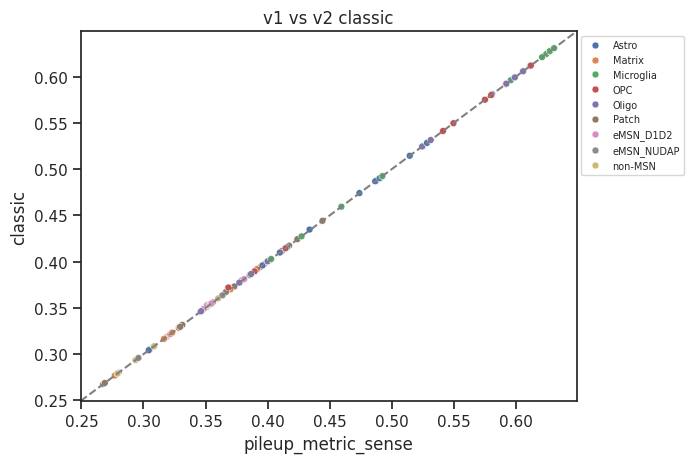

In [15]:
cells_an = obs_cells[~obs_cells["excluded"] & obs_cells["ct_for_deg"].isin(CORE_CT)].copy()
pb_ct = pseudobulk(cells_an, ["donor_id", "donor_number", "condition", "ct_for_deg"])
pb_ct = pb_ct.merge(lib_meta.groupby("donor_id")["run"].agg(lambda s: "+".join(sorted(set(s)))).rename("runs"), on="donor_id", how="left")

if V1_PER_DONOR_CSV is not None and Path(V1_PER_DONOR_CSV).exists():
    v1 = pd.read_csv(V1_PER_DONOR_CSV)[["donor_id", "ct_for_deg", "pileup_metric_sense"]]
    cmp_v1 = pb_ct[["donor_id", "ct_for_deg", "classic"]].merge(v1, on=["donor_id", "ct_for_deg"]).dropna()
    print(f"n={len(cmp_v1)}  max |v1 - v2| = {np.abs(cmp_v1['classic'] - cmp_v1['pileup_metric_sense']).max():.4f}  "
          f"pearson r = {np.corrcoef(cmp_v1['classic'], cmp_v1['pileup_metric_sense'])[0, 1]:.4f}")
    ax = sns.scatterplot(cmp_v1, x="pileup_metric_sense", y="classic", hue="ct_for_deg", s=25)
    ax.axline((0.3, 0.3), slope=1, c="0.5", ls="--"); ax.legend(fontsize=7, bbox_to_anchor=(1, 1)); plt.title("v1 vs v2 classic"); plt.show()
else:
    print("v1 csv not found -> check skipped")

# Main analysis: Control vs XDP per cell type

**How to read the metrics together** (decide this before looking):
- `specific` and `readthrough` ↑ in XDP while `neg_ctrl` is flat → excess of intron-32 signal specific to the region before the SVA (32i).
- `neg_ctrl` ↑ as well → a global intronic shift is (at least partly) driving `classic`; look at the adjusted log2OR and at the `pct_intronic` plots.
- decomposition (`cp10k_*`): does `pre` go up, or does TAF1 3′ output (`cp10k_post_exonic_s`) go down, or both?
- `IR` uses sparse junction reads: exploratory.

classic         exonic        readthrough        specific         \
condition  Control    XDP Control    XDP     Control    XDP  Control    XDP   
ct_for_deg                                                                    
Astro         4989  20272    2687  12809        2538  12058     4539  18777   
Matrix       27428  26059   12615  13723       12686  13192    22874  20517   
Microglia     2188   9606    1304   6978        1333   7090     2119   9742   
OPC           1269   4352     694   3056         685   3056     1106   4272   
Oligo        16483  76814    8868  53283        8138  50585    15895  75080   
Patch         8446   9772    3843   5342        3795   5281     6908   7926   
eMSN_D1D2     1885   4682     884   2370         858   2343     1485   3576   
eMSN_NUDAP     744   8235     348   4045         335   4003      538   6067   
non-MSN       9671  45760    4342  23002        4357  22571     8297  34503   

           neg_ctrl             IR       as_pre        as_postSVA         
condition   Control    XDP Control  XDP Control    XDP    Control    XDP  
ct_for_deg                                                                
Astro          3456  11752      52  181     982   3921        874   3156  
Matrix        18719  14738     116  121    5122   5258       4568   4306  
Microglia      1453   4782      16   55     385   1538        346   1091  
OPC             786   2286      11   32     227    762        194    583  
Oligo         12521  40795     131  581    3242  13531       2892  10006  
Patch          5611   5390      38   47    1580   1846       1380   1534  
eMSN_D1D2      1179   2490      10   15     328    778        307    703  
eMSN_NUDAP      452   4354       3   37     155   1388        138   1225  
non-MSN        6967  25997      37  247    1762   8759       1625   7847

metric,classic,exonic,readthrough,specific,neg_ctrl,IR,as_pre,as_postSVA
ct,,,,,,,,
Matrix,0.46,0.34,0.55,0.61,-0.27,0.51,0.61,0.05
Patch,0.55,0.35,0.46,0.76,-0.40,NaN,0.69,0.37
eMSN_D1D2,0.28,0.16,0.29,0.56,-0.38,NaN,1.47,0.60
eMSN_NUDAP,0.37,0.58,0.53,0.43,0.16,NaN,0.10,-0.17
non-MSN,0.36,0.27,0.28,0.61,-0.32,NaN,0.09,-0.10
Oligo,1.05,0.92,0.90,0.84,0.07,0.77,1.09,0.11
OPC,1.05,0.80,0.72,0.76,0.04,NaN,0.94,0.84
Astro,0.72,0.62,0.67,0.58,0.05,0.94,0.76,0.09
Microglia,1.02,0.96,0.89,0.77,0.20,NaN,1.21,-0.10


metric,classic,exonic,readthrough,specific,neg_ctrl,IR,as_pre,as_postSVA
ct,,,,,,,,
Matrix,0.003,0.009,0.003,0.012,0.148,0.343,0.045,0.861
Patch,0.003,0.009,0.006,0.006,0.018,NaN,0.062,0.400
eMSN_D1D2,0.203,0.264,0.197,0.009,0.173,NaN,0.083,0.429
eMSN_NUDAP,0.082,0.033,0.025,0.100,0.475,NaN,0.929,0.857
non-MSN,0.070,0.327,0.212,0.015,0.085,NaN,0.906,0.600
Oligo,0.003,0.012,0.003,0.030,0.733,0.245,0.067,0.570
OPC,0.003,0.012,0.003,0.003,0.891,NaN,0.206,0.292
Astro,0.003,0.045,0.003,0.021,0.912,0.224,0.161,0.724
Microglia,0.003,0.003,0.003,0.003,0.355,NaN,0.088,0.873


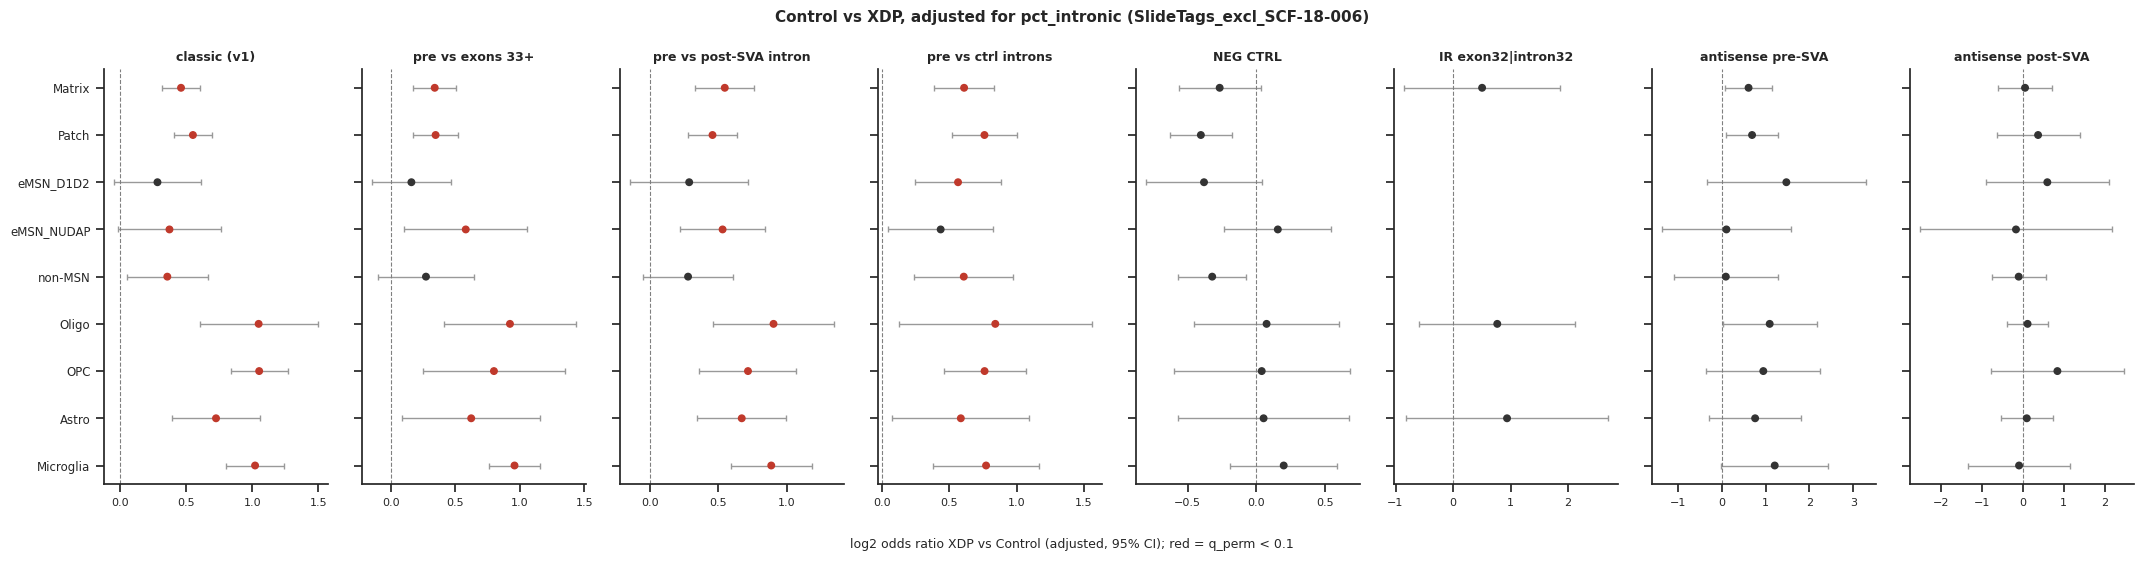

In [16]:
MAIN_METRICS = ["classic", "exonic", "readthrough", "specific", "neg_ctrl", "IR", "as_pre", "as_postSVA"]

res_main = run_suite(pb_ct, MAIN_METRICS + ABUNDANCE_METRICS, CORE_CT, "main")
res_main.to_csv(OUT_DIR / f"32i_v2_tests_main_{ANALYSIS_NAME}.csv", index=False)

# how much signal per metric (UMIs in the denominators, summed per condition)
den = []
for m in FRACTION_METRICS:
    s = pb_ct.groupby(["condition", "ct_for_deg"])[[METRICS[m]["num"], METRICS[m]["other"]]].sum().sum(axis=1).rename(m)
    den.append(s)
display(pd.concat(den, axis=1).astype(int).unstack(0))

display(res_main.pivot_table(index="ct", columns="metric", values="log2OR_adj", sort=False).reindex(columns=MAIN_METRICS).round(2))
display(res_main.pivot_table(index="ct", columns="metric", values="p_perm_adj", sort=False).reindex(columns=MAIN_METRICS).round(3))
plot_forest(res_main, MAIN_METRICS, CORE_CT, f"Control vs XDP, adjusted for {', '.join(COVARIATE_ADJUST)} ({ANALYSIS_NAME})")

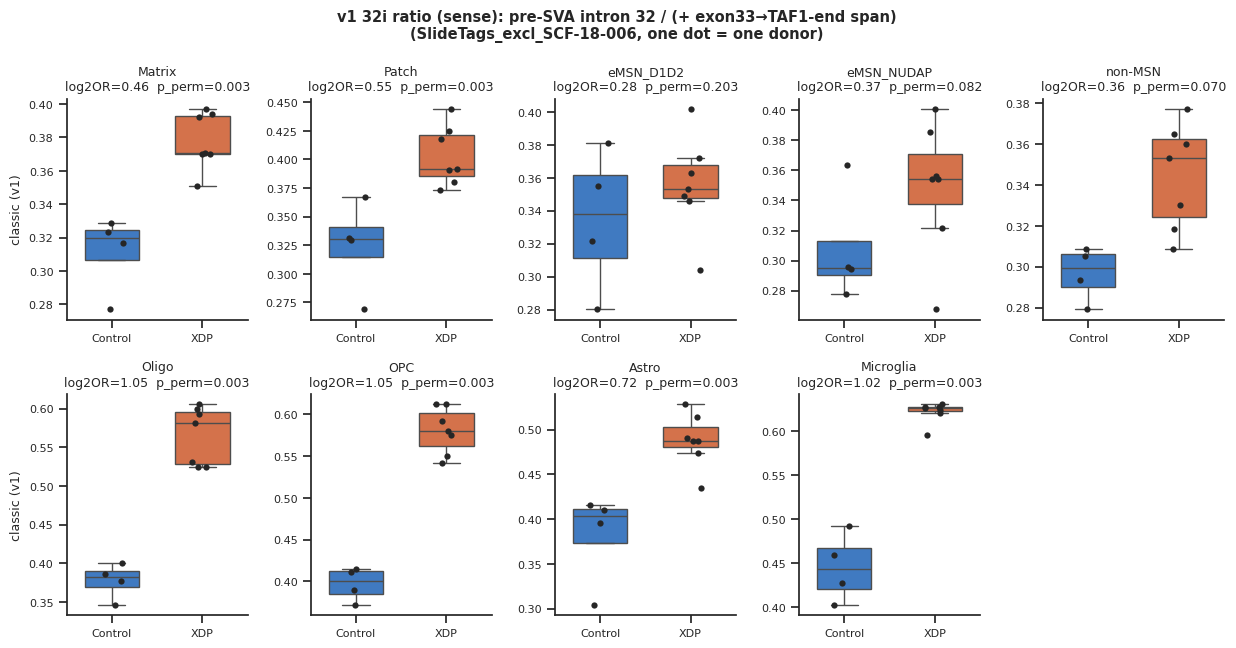

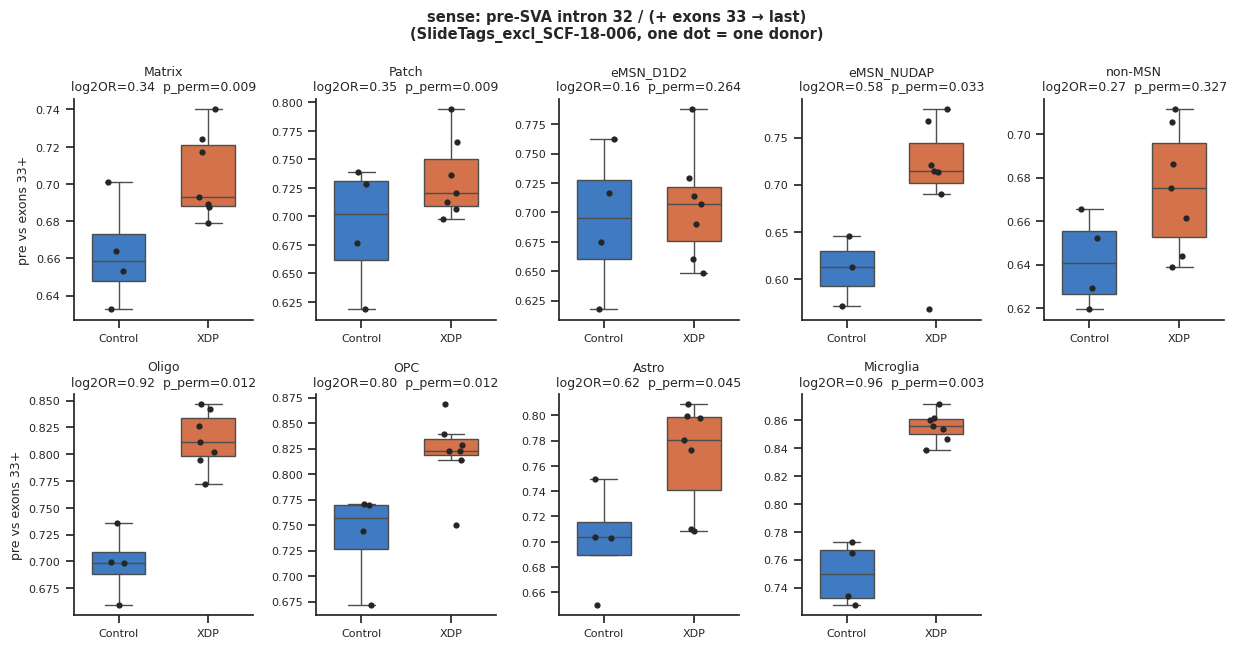

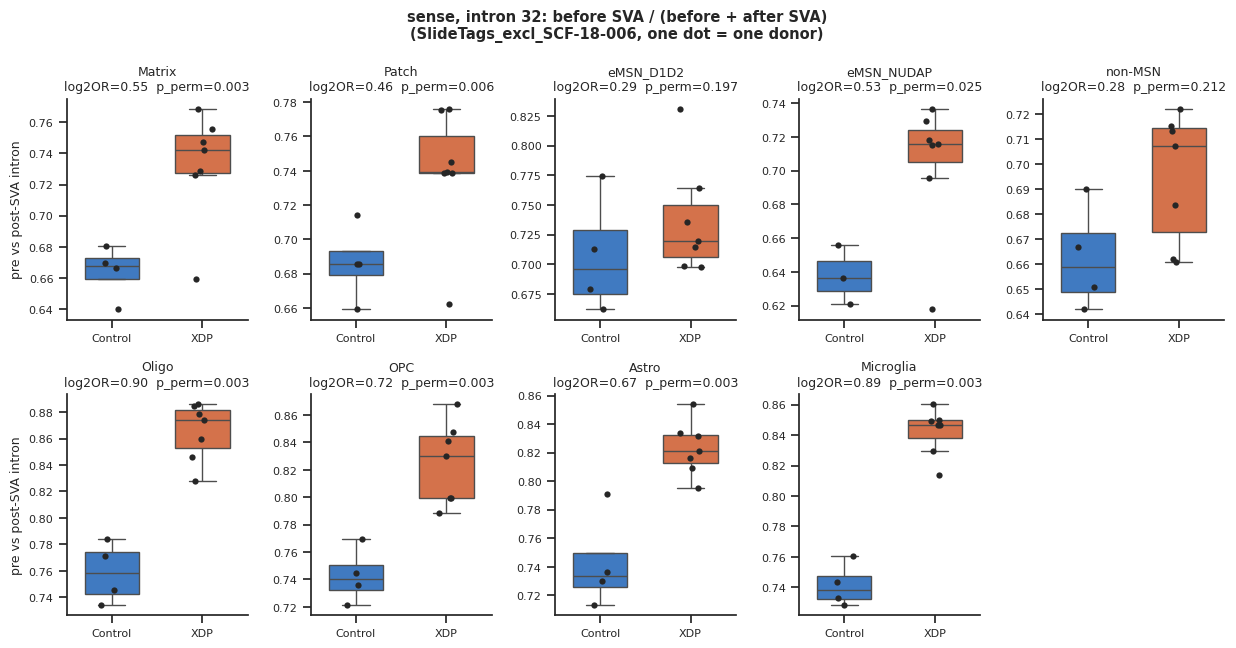

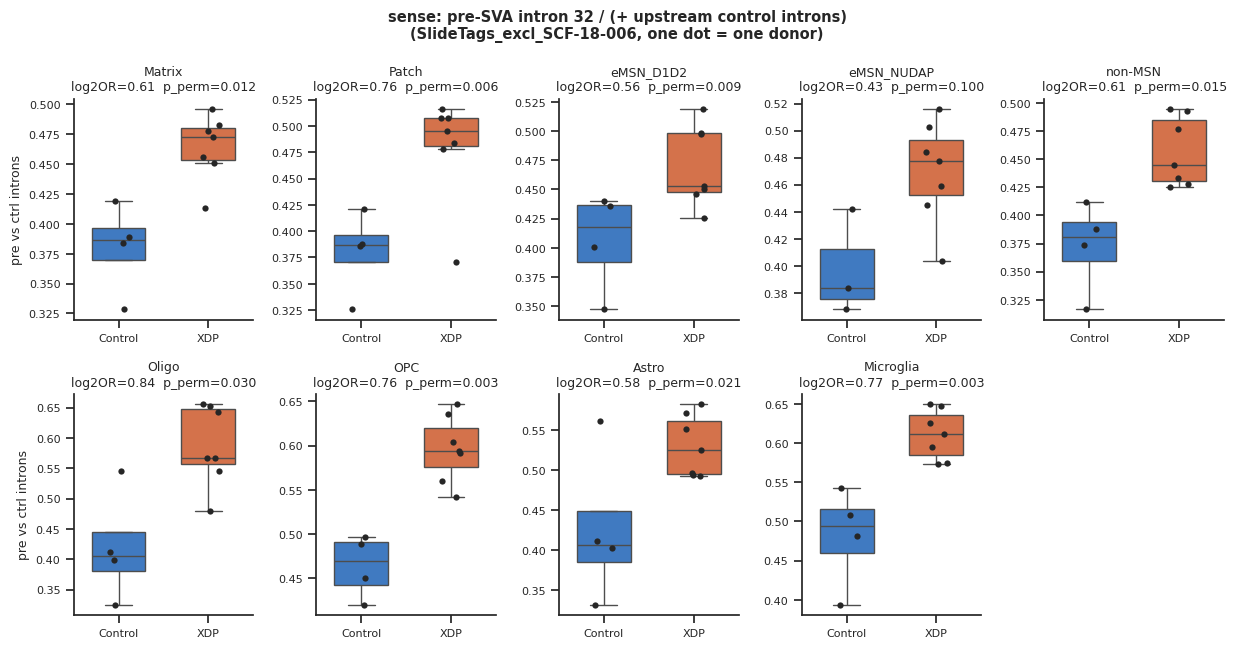

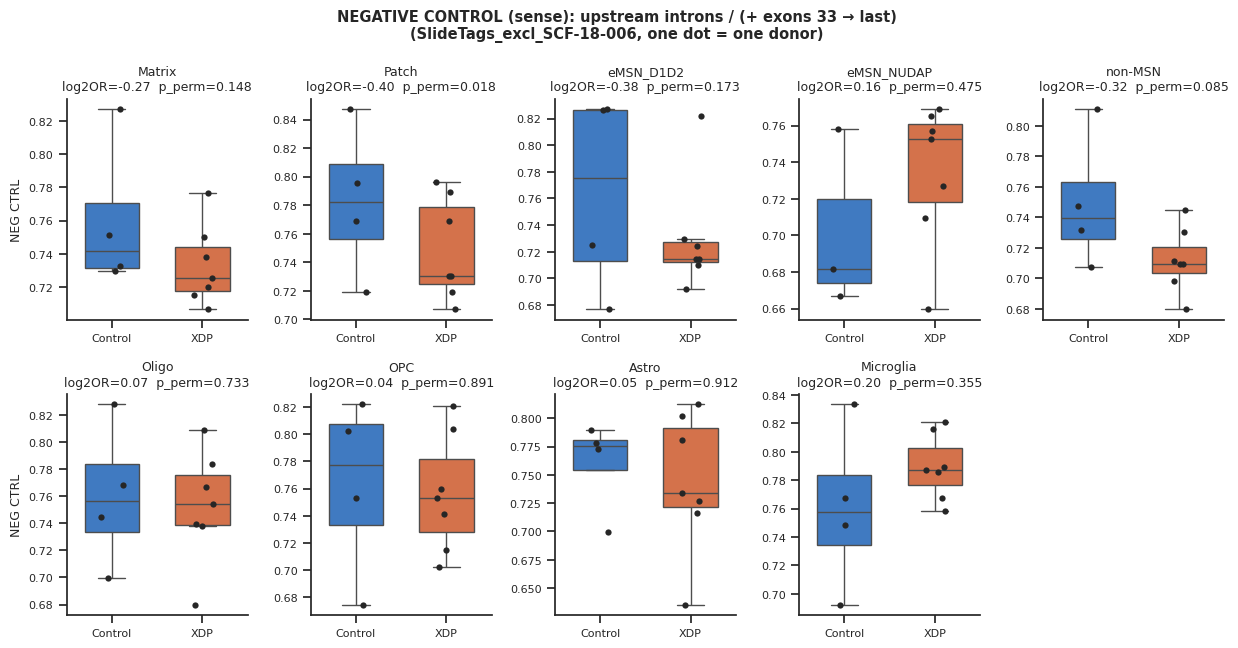

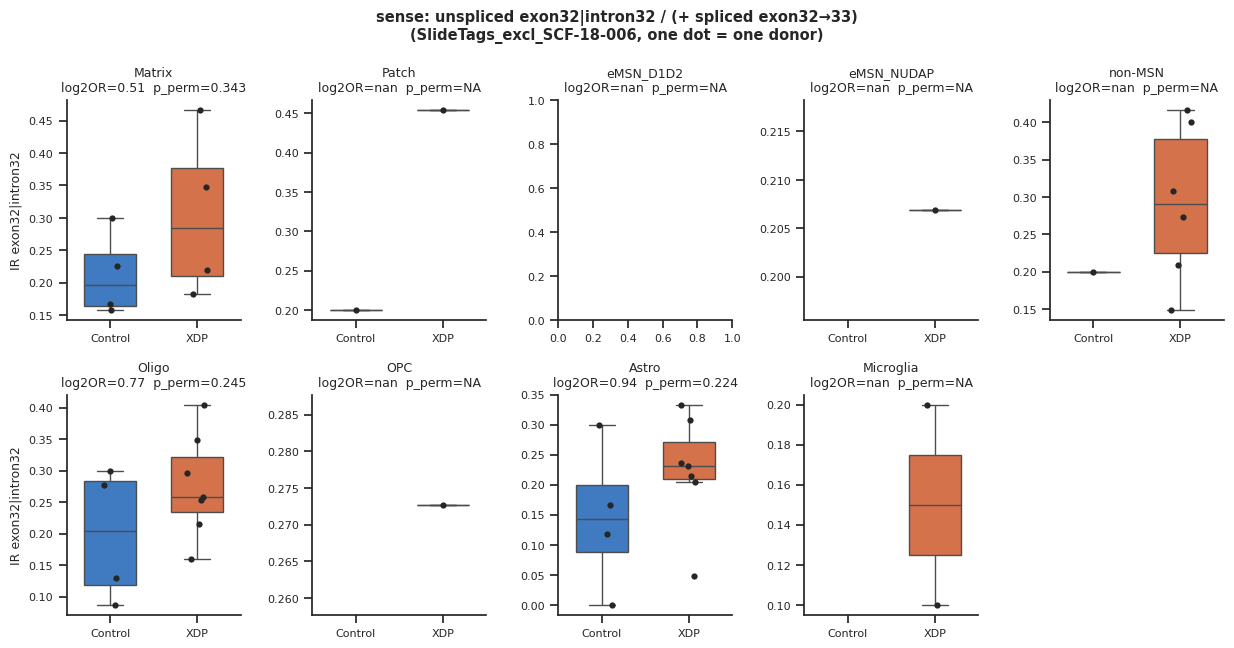

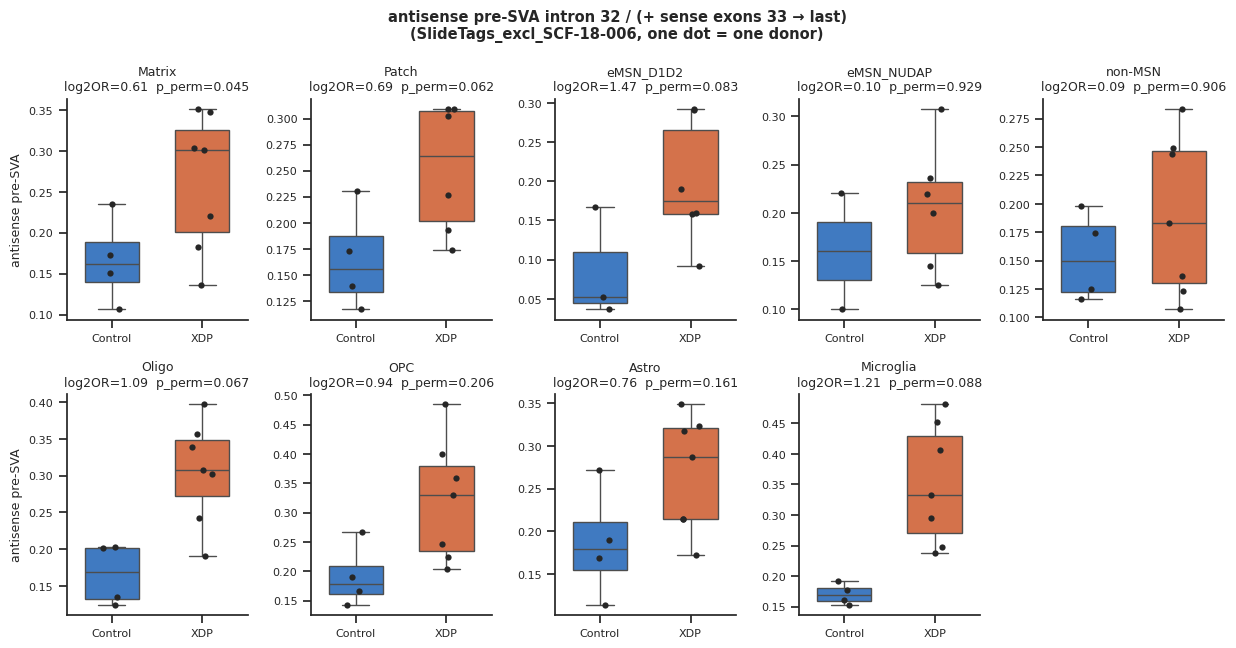

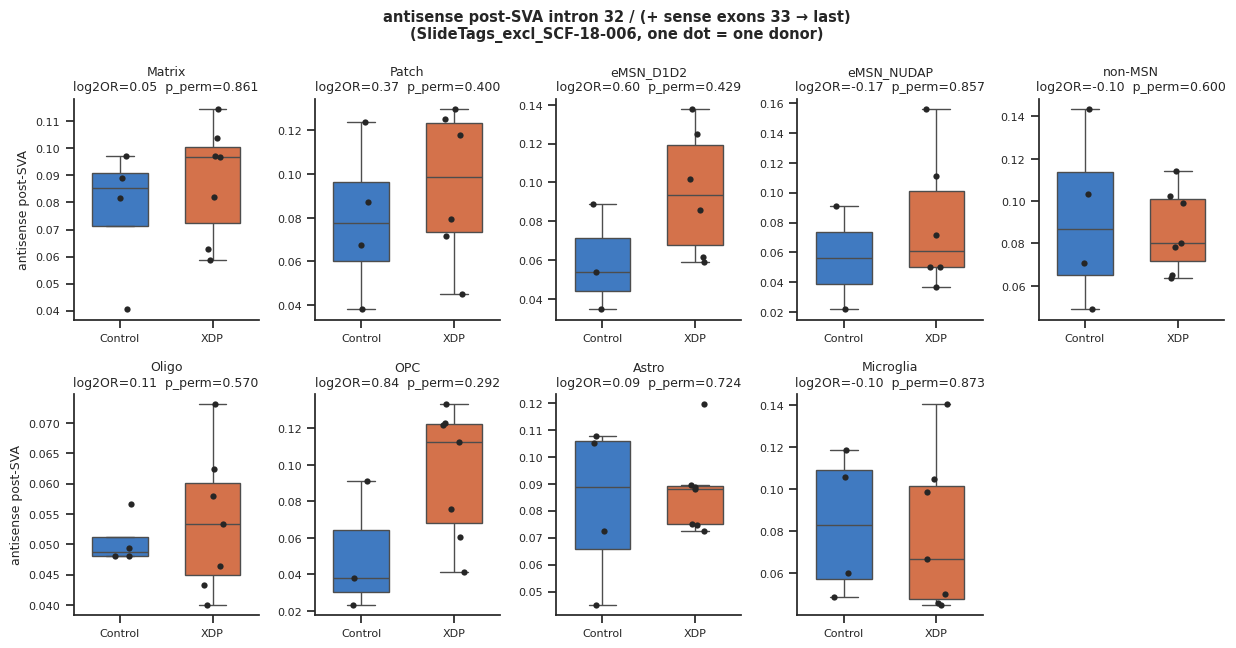

In [17]:
for m in MAIN_METRICS:
    plot_donor_dots(pb_ct, m, CORE_CT, res_main)

## Decomposition: what changes, numerator or denominator?
Per-10k-UMI abundances of each window. Note that per-10k values are affected by global composition of the transcriptome (e.g. more glial / stress transcripts), so read them as a complement to the ratios, not as absolute expression.

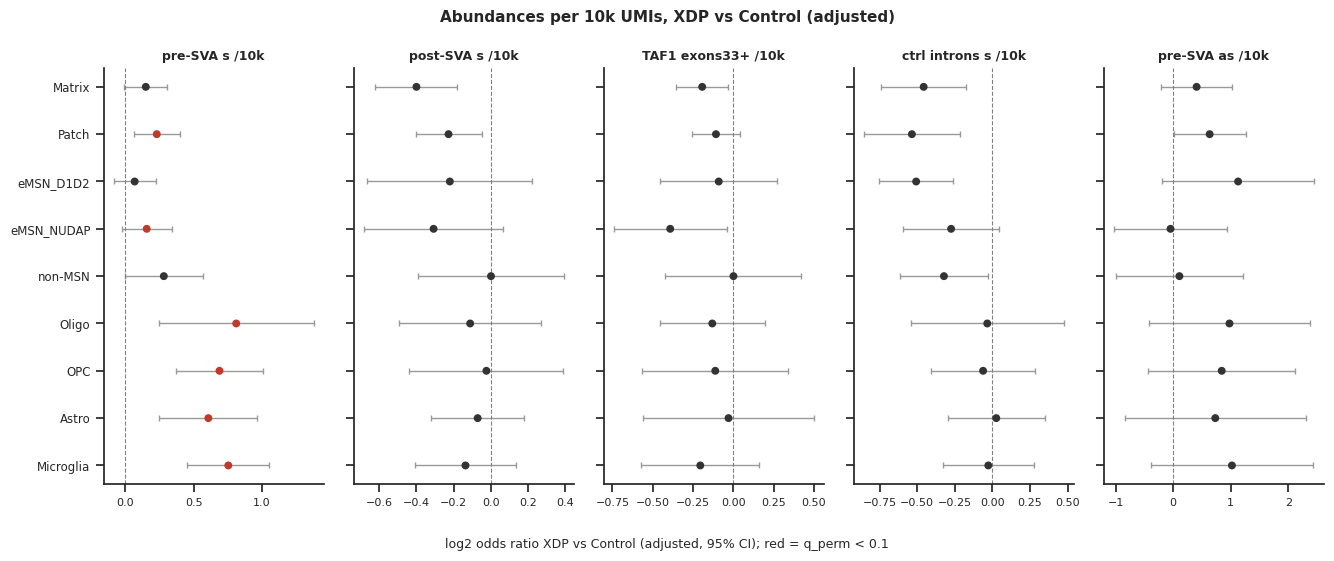

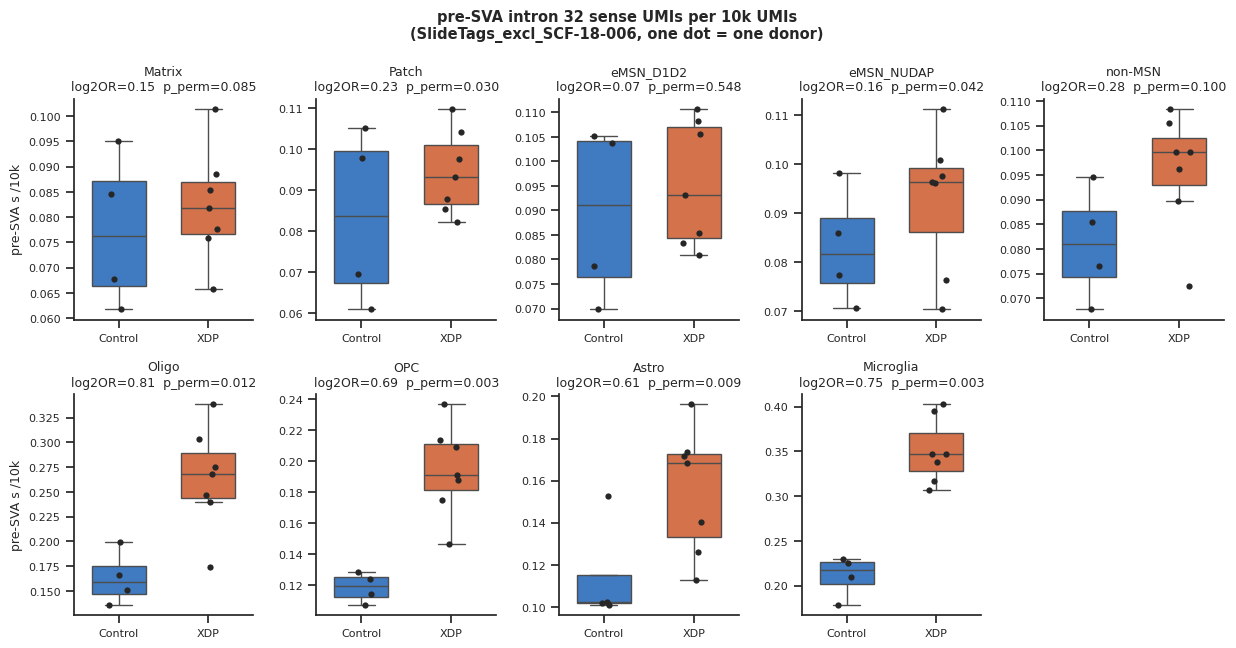

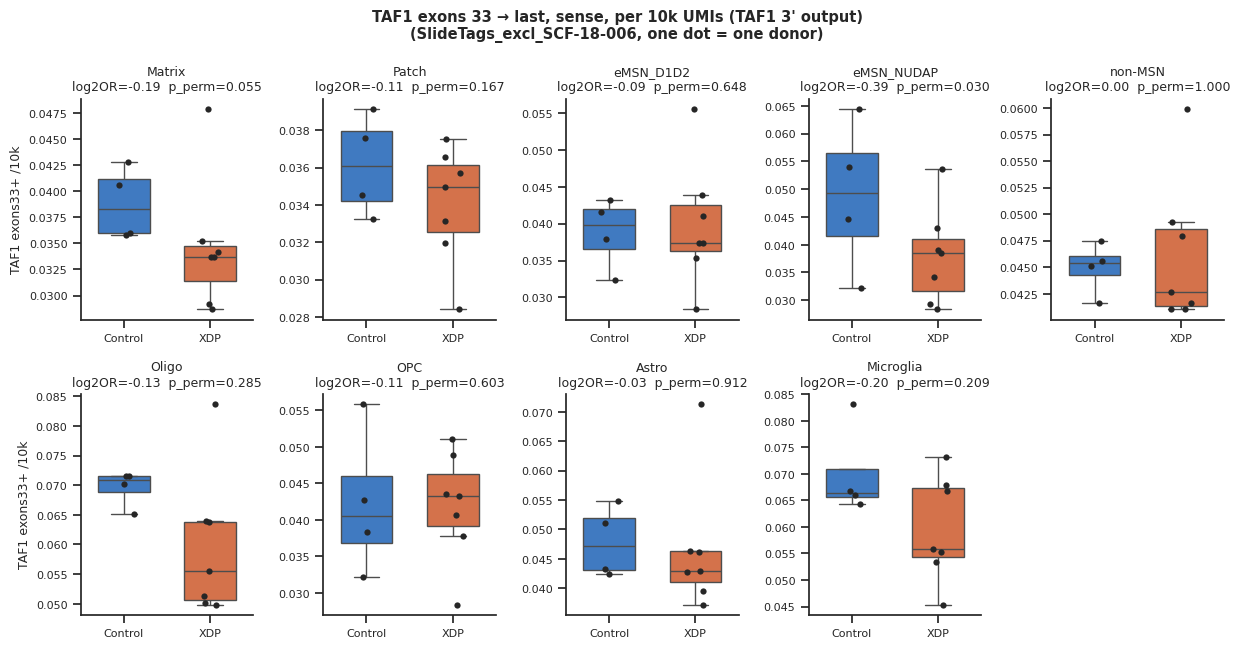

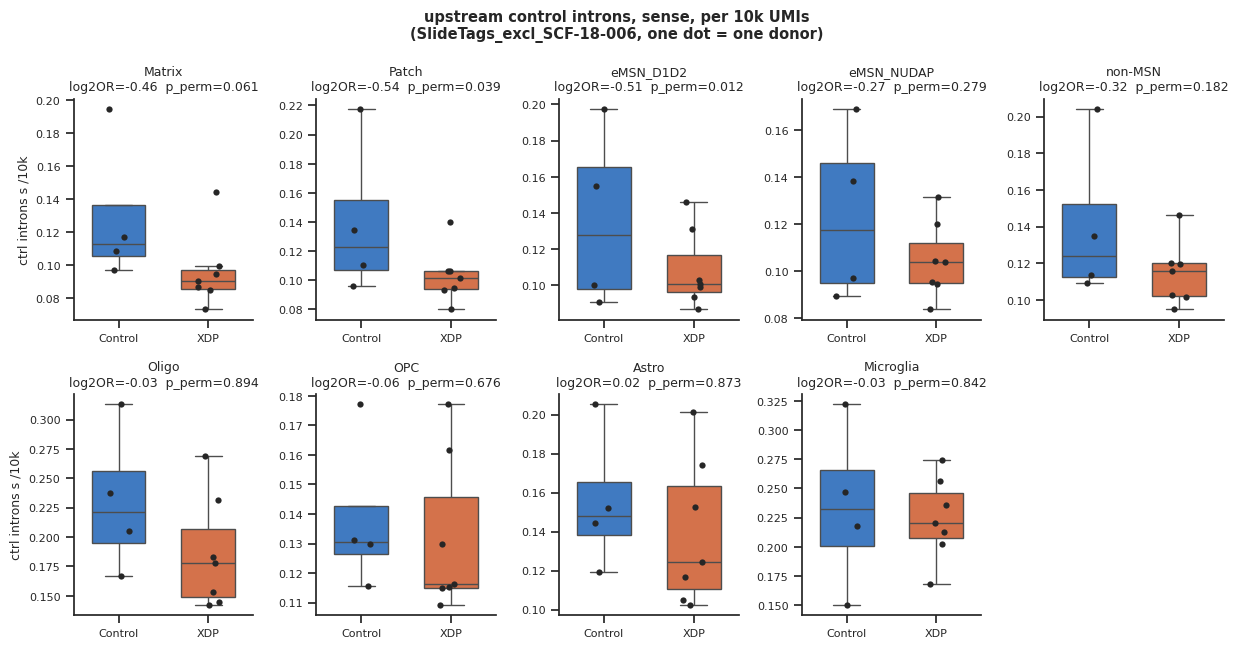

In [18]:
plot_forest(res_main, ABUNDANCE_METRICS, CORE_CT, "Abundances per 10k UMIs, XDP vs Control (adjusted)")
for m in ["cp10k_pre_s", "cp10k_post_exonic_s", "cp10k_ctrl_intron_s"]:
    plot_donor_dots(pb_ct, m, CORE_CT, res_main)

## Composition-standardised "all cells"
Mean of the per-cell-type ratios (equal weight per cell type, only cell types measurable in every donor), instead of pooling UMIs. Exact permutation test on the difference of means.

/tmp/ipykernel_30965/3588334099.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  w = pb[pb["ct_for_deg"].isin(cts)].pivot_table(index=["donor_id", "condition"], columns="ct_for_deg", values=metric)
/tmp/ipykernel_30965/3588334099.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  w = pb[pb["ct_for_deg"].isin(cts)].pivot_table(index=["donor_id", "condition"], columns="ct_for_deg", values=metric)
/tmp/ipykernel_30965/3588334099.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  w = pb[pb["ct_for_deg"

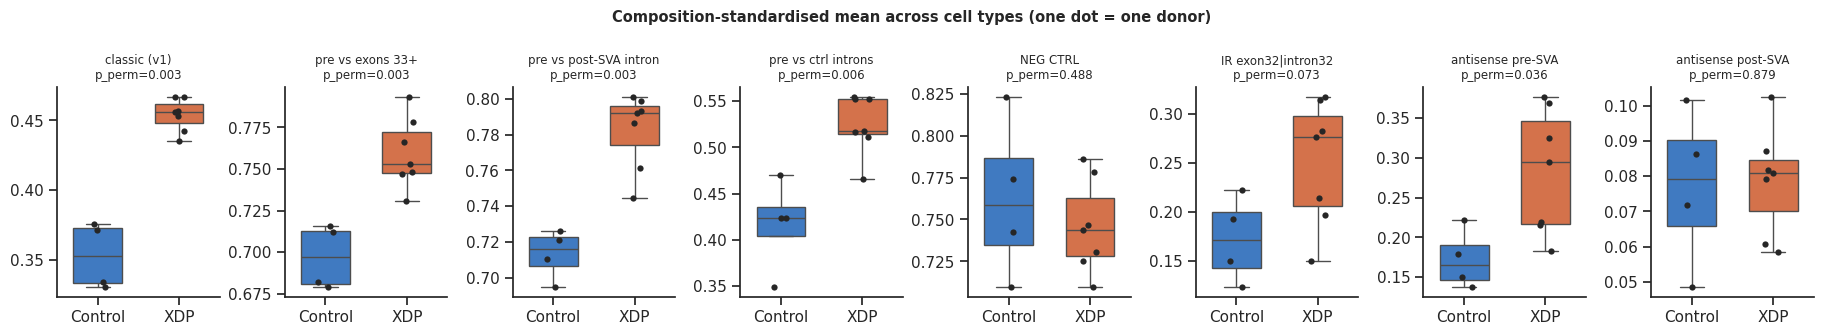

,metric,cell_types_used,mean_control,mean_xdp,p_perm
0,classic,"Astro, Matrix, Microglia, OPC, Oligo, Patch, e...",0.352931,0.454023,0.003030
1,exonic,"Astro, Matrix, Microglia, OPC, Oligo, Patch, e...",0.697030,0.759475,0.003030
2,readthrough,"Astro, Matrix, Microglia, OPC, Oligo, Patch, e...",0.713174,0.782451,0.003030
3,specific,"Astro, Matrix, Microglia, OPC, Oligo, Patch, e...",0.416398,0.524433,0.006061
4,neg_ctrl,"Astro, Matrix, Microglia, OPC, Oligo, Patch, e...",0.762519,0.745779,0.487879
5,IR,"Astro, Oligo",0.172260,0.250674,0.072727
6,as_pre,"Astro, Matrix, Microglia, OPC, Oligo, non-MSN",0.172394,0.283048,0.036364
7,as_postSVA,"Astro, Matrix, Microglia, Oligo, non-MSN",0.077041,0.078701,0.878788


In [19]:
def standardized_all_cells(pb, metric, cts):
    w = pb[pb["ct_for_deg"].isin(cts)].pivot_table(index=["donor_id", "condition"], columns="ct_for_deg", values=metric)
    w = w.dropna(axis=1)
    return w.mean(axis=1).rename(metric).reset_index(), list(w.columns)


def perm_mean_diff(values, cond):
    values, cond = np.asarray(values, float), np.asarray(cond, int)
    obs = abs(values[cond == 1].mean() - values[cond == 0].mean())
    N, k = len(values), cond.sum()
    diffs = []
    for idx in itertools.combinations(range(N), k):
        c = np.zeros(N, bool); c[list(idx)] = True
        diffs.append(abs(values[c].mean() - values[~c].mean()))
    return np.mean(np.array(diffs) >= obs - 1e-12)


rows = []
fig, axes = plt.subplots(1, len(MAIN_METRICS), figsize=(2.3 * len(MAIN_METRICS), 3.4))
for ax, m in zip(axes, MAIN_METRICS):
    s, used = standardized_all_cells(pb_ct, m, CORE_CT)
    cond = (s["condition"].astype(str) == "XDP").astype(int).values
    p = perm_mean_diff(s[m], cond) if len(used) and cond.sum() >= 2 and (1 - cond).sum() >= 2 else np.nan
    rows.append({"metric": m, "cell_types_used": ", ".join(used), "mean_control": s.loc[cond == 0, m].mean(),
                 "mean_xdp": s.loc[cond == 1, m].mean(), "p_perm": p})
    s = s.dropna(subset=[m])
    if len(s):
        sns.boxplot(s, x="condition", y=m, order=["Control", "XDP"], hue="condition", palette=CONDITION_COLORS,
                    showfliers=False, legend=False, ax=ax, width=0.6)
        sns.stripplot(s, x="condition", y=m, order=["Control", "XDP"], color="0.15", size=4.5, ax=ax)
    ax.set_title(f"{METRICS[m]['short']}\np_perm={fmt_p(p)}", fontsize=8.5); ax.set_xlabel(""); ax.set_ylabel("")
    sns.despine(ax=ax)
fig.suptitle("Composition-standardised mean across cell types (one dot = one donor)", fontweight="bold", fontsize=10.5)
fig.tight_layout(); plt.show()
display(pd.DataFrame(rows))

## Is it a global intronic effect?
Each metric vs the pseudobulk `pct_intronic`, all donors. A metric that tracks `pct_intronic` in both conditions (and `neg_ctrl` doing the same) points to a technical / global component.

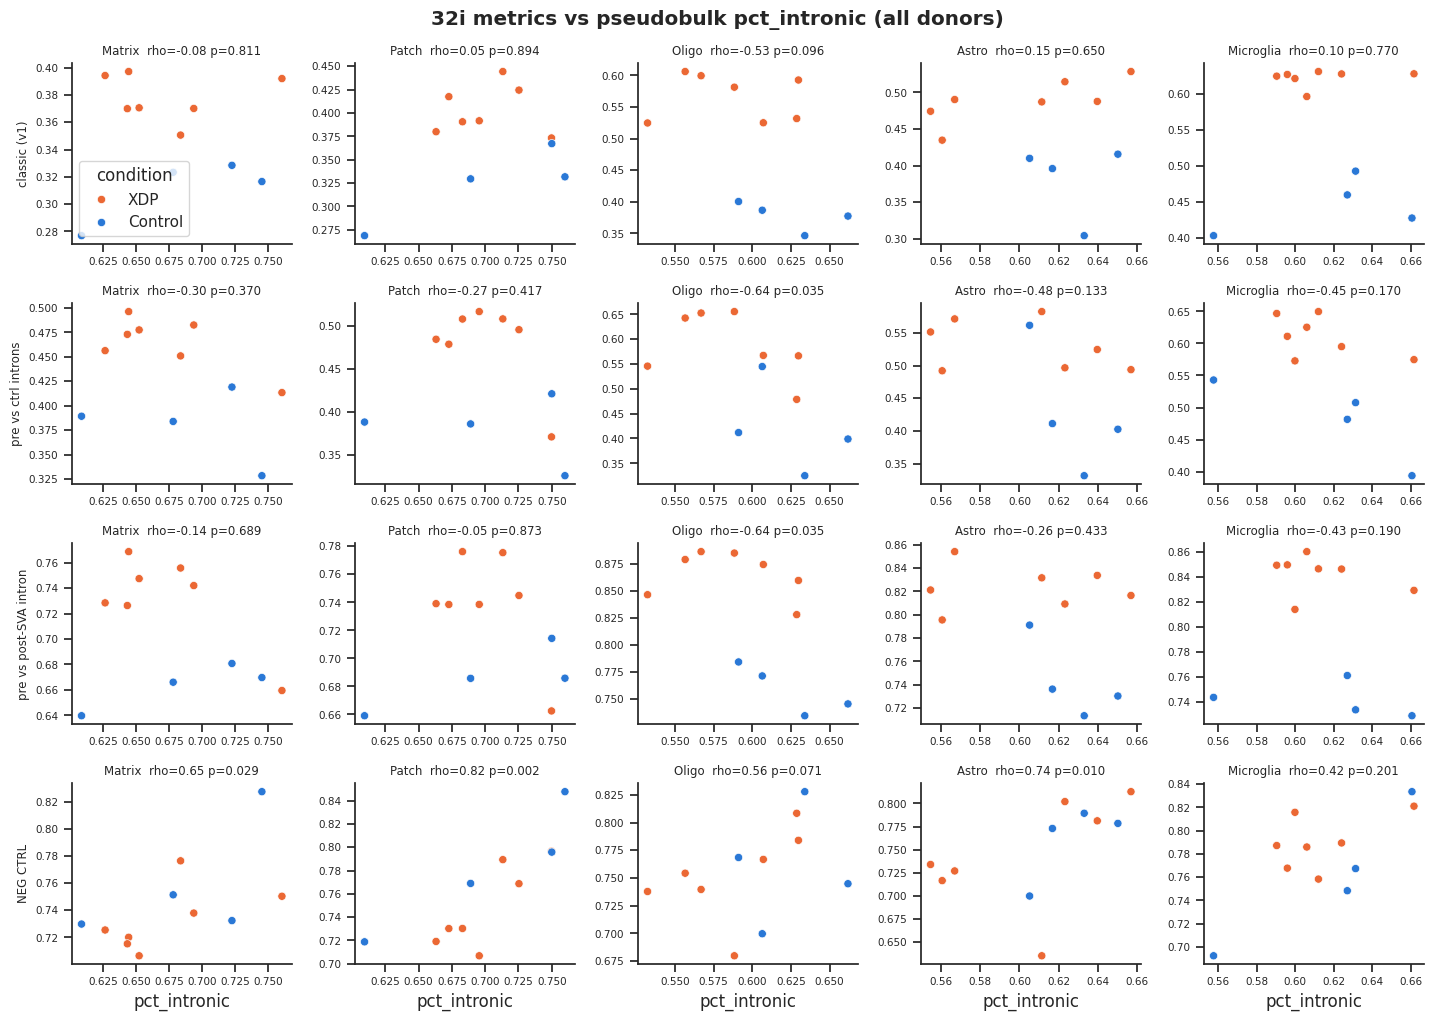

In [20]:
CHECK_METRICS = ["classic", "specific", "readthrough", "neg_ctrl"]
CHECK_CT = ["Matrix", "Patch", "Oligo", "Astro", "Microglia"]
fig, axes = plt.subplots(len(CHECK_METRICS), len(CHECK_CT), figsize=(2.9 * len(CHECK_CT), 2.6 * len(CHECK_METRICS)), squeeze=False)
for i, m in enumerate(CHECK_METRICS):
    for j, ct in enumerate(CHECK_CT):
        ax = axes[i, j]
        d = pb_ct[pb_ct["ct_for_deg"] == ct].dropna(subset=[m, "pct_intronic"])
        sns.scatterplot(d, x="pct_intronic", y=m, hue="condition", palette=CONDITION_COLORS, ax=ax, legend=(i == 0 and j == 0), s=35)
        if len(d) >= 4:
            rho, p = stats.spearmanr(d["pct_intronic"], d[m])
            ax.set_title(f"{ct}  rho={rho:.2f} p={fmt_p(p)}", fontsize=8.5)
        ax.set_ylabel(METRICS[m]["short"] if j == 0 else "", fontsize=8.5); ax.set_xlabel("pct_intronic" if i == len(CHECK_METRICS) - 1 else "")
        ax.tick_params(labelsize=7.5); sns.despine(ax=ax)
fig.suptitle("32i metrics vs pseudobulk pct_intronic (all donors)", fontweight="bold")
fig.tight_layout(); plt.show()

# Per-library reproducibility, run and sorting
Pseudobulk per library × cell class. Libraries of the same donor should agree; a run or Sorted effect shows up as colour/marker structure. Excluded donor shown (grey label).

In [21]:
cells_lib = obs_cells[obs_cells["ct_for_deg"].isin(CORE_CT)].copy()
pb_lib = pseudobulk(cells_lib, ["library_id", "run", "Sorted", "donor_id", "donor_number", "condition", "excluded", "ct_class"]) \
    if "Sorted" in cells_lib else pseudobulk(cells_lib.assign(Sorted="NA"), ["library_id", "run", "Sorted", "donor_id", "donor_number", "condition", "excluded", "ct_class"])

QC_METRICS = ["classic", "readthrough", "specific", "neg_ctrl"]
donor_order = (pb_lib.sort_values(["condition", "donor_number"])["donor_number"].unique().tolist())
pos = {d: i for i, d in enumerate(donor_order)}
run_pal = dict(zip(sorted(pb_lib["run"].unique()), sns.color_palette("tab10", pb_lib["run"].nunique())))
sorted_vals = sorted(pb_lib["Sorted"].astype(str).unique())
offset = {s: (k - (len(sorted_vals) - 1) / 2) * 0.25 for k, s in enumerate(sorted_vals)}

for cls in CLASSES:
    d = pb_lib[pb_lib["ct_class"] == cls].copy()
    d["xpos"] = d["donor_number"].map(pos) + d["Sorted"].astype(str).map(offset)
    fig, axes = plt.subplots(1, len(QC_METRICS), figsize=(4.6 * len(QC_METRICS), 3.6))
    for ax, m in zip(axes, QC_METRICS):
        sns.scatterplot(d, x="xpos", y=m, hue="run", style="Sorted", palette=run_pal, s=45, ax=ax, legend=(m == QC_METRICS[-1]))
        ax.set_xticks(range(len(donor_order)))
        ax.set_xticklabels(donor_order, rotation=90, fontsize=7.5)
        for t in ax.get_xticklabels():
            if pb_lib.loc[pb_lib["donor_number"] == t.get_text(), "excluded"].any():
                t.set_color("0.6")
        n_ctrl = (pb_lib.drop_duplicates("donor_number")["condition"] == "Control").sum()
        ax.axvline(n_ctrl - 0.5, c="0.7", ls=":")
        ax.set_title(METRICS[m]["short"], fontsize=9.5); ax.set_xlabel(""); ax.set_ylabel("")
        sns.despine(ax=ax)
    axes[-1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"{cls}: one dot = one library (Control | XDP)", fontweight="bold")
    fig.tight_layout(); plt.show()

# how much of the variance is within donor (between libraries) vs between donors, on the logit scale
var_rows = []
for cls in CLASSES:
    for m in QC_METRICS:
        d = pb_lib[(pb_lib["ct_class"] == cls) & ~pb_lib["excluded"]].dropna(subset=[m])
        d = d[d.groupby("donor_id")["library_id"].transform("size") >= 2]
        if d["donor_id"].nunique() < 3:
            continue
        lv = np.log(d[m].clip(1e-4, 1 - 1e-4) / (1 - d[m].clip(1e-4, 1 - 1e-4)))
        within = lv.groupby(d["donor_id"]).var(ddof=1).mean()
        between = lv.groupby(d["donor_id"]).mean().var(ddof=1)
        var_rows.append({"class": cls, "metric": m, "var_within_donor": within, "var_between_donor": between,
                         "frac_within": within / (within + between)})
display(pd.DataFrame(var_rows).round(3))

TypeError: Object with dtype category cannot perform the numpy op add

# Sensitivity analyses
1. **Sorting**: neurons only from NeuN+ libraries, glia only from Unsorted libraries.
2. **sample_09 included** (paired-end run, strand already handled by `fragment_is_reverse`).
3. **Unadjusted vs adjusted**: compare `log2OR` and `log2OR_adj` in the main table.

In [ ]:
SENS_METRICS = ["classic", "readthrough", "specific", "neg_ctrl"]
sens = [res_main[res_main["metric"].isin(SENS_METRICS)]]

if "Sorted" in cells_an:
    is_neun = cells_an["Sorted"].astype(str).str.contains("neun", case=False)
    is_neuron = cells_an["ct_class"] == "Neuron"
    cells_sorted = cells_an[(is_neuron & is_neun) | (~is_neuron & ~is_neun)]
    pb_sorted = pseudobulk(cells_sorted, ["donor_id", "donor_number", "condition", "ct_for_deg"])
    sens.append(run_suite(pb_sorted, SENS_METRICS, CORE_CT, "neurons NeuN+ / glia Unsorted"))

cells_all_donors = obs_cells[obs_cells["ct_for_deg"].isin(CORE_CT)]
pb_all_donors = pseudobulk(cells_all_donors, ["donor_id", "donor_number", "condition", "ct_for_deg"])
sens.append(run_suite(pb_all_donors, SENS_METRICS, CORE_CT, "all donors (incl. excluded)"))

df_sens = pd.concat(sens, ignore_index=True)
df_sens.to_csv(OUT_DIR / f"32i_v2_tests_sensitivity_{ANALYSIS_NAME}.csv", index=False)
display(df_sens.pivot_table(index=["metric", "ct"], columns="analysis", values="log2OR_adj", sort=False).round(2))
display(df_sens.pivot_table(index=["metric", "ct"], columns="analysis", values="p_perm_adj", sort=False).round(3))

# Ambient RNA
Non-cell barcodes summed per library vs the called cells of the same library. If the ambient ratio is close to the glial ratio, part of the glial signal could be ambient. Caveat: "non-cell" = not in the adata, so it includes cells removed by QC.

In [ ]:
amb = df_ambient.copy()
amb["total_umis"] = np.nan          # unknown for non-cell barcodes -> abundance metrics NaN
amb["intronic_umis"] = np.nan
amb = compute_metrics(amb).merge(lib_meta, on="library_id")
lib_cells = pseudobulk(obs_cells, ["library_id"]).merge(lib_meta, on="library_id")
AMB_METRICS = ["classic", "exonic", "readthrough", "specific", "neg_ctrl"]
cmp_amb = lib_cells[["library_id", "condition", *AMB_METRICS, "pre_s"]].merge(
    amb[["library_id", "n_barcodes", *AMB_METRICS, "pre_s"]], on="library_id", suffixes=("_cells", "_ambient"))
cmp_amb["ambient_pre_UMIs_per_cell_pre_UMI"] = cmp_amb["pre_s_ambient"] / cmp_amb["pre_s_cells"]

fig, axes = plt.subplots(1, len(AMB_METRICS), figsize=(3.2 * len(AMB_METRICS), 3.2))
for ax, m in zip(axes, AMB_METRICS):
    sns.scatterplot(cmp_amb, x=f"{m}_cells", y=f"{m}_ambient", hue="condition", palette=CONDITION_COLORS, ax=ax, legend=(m == AMB_METRICS[0]))
    lo = np.nanmin(cmp_amb[[f"{m}_cells", f"{m}_ambient"]].values); hi = np.nanmax(cmp_amb[[f"{m}_cells", f"{m}_ambient"]].values)
    if np.isfinite(lo) and np.isfinite(hi):
        ax.plot([lo, hi], [lo, hi], c="0.6", ls="--")
    ax.set_title(METRICS[m]["short"], fontsize=9); sns.despine(ax=ax)
fig.suptitle("Per library: called cells (x) vs non-cell barcodes (y)", fontweight="bold"); fig.tight_layout(); plt.show()
display(cmp_amb[["library_id", "condition", "n_barcodes", "ambient_pre_UMIs_per_cell_pre_UMI"]].describe())

# Coverage profile along TAF1 (control introns → intron 32 → 3′ end)
UMIs per bin, per donor and cell class, normalised to 1000 sense `post_exonic` UMIs of the same donor × class, mean ± s.e.m. across donors. A localised excess just before the SVA = 32i pile-up / termination; a uniform increase across all introns = global intronic shift.

In [ ]:
prof = df_prof.merge(lib_meta, on="library_id")
prof = prof[~prof["excluded"]]
prof["ct_class"] = prof["ct_for_deg"].map(CT_CLASS)
prof = prof[prof["ct_for_deg"].isin(CORE_CT)]
prof_d = prof.groupby(["donor_id", "condition", "ct_class", "strand", "bin"])["n_umis"].sum()

pb_class = pseudobulk(cells_an, ["donor_id", "donor_number", "condition", "ct_class"])
norm = pb_class.set_index(["donor_id", "ct_class"])["post_exonic_s"]

idx = pd.MultiIndex.from_product([pb_class["donor_id"].unique(), CLASSES, ["s", "as"], range(N_BINS)],
                                 names=["donor_id", "ct_class", "strand", "bin"])
prof_full = (prof_d.reset_index().drop(columns="condition").set_index(["donor_id", "ct_class", "strand", "bin"])["n_umis"]
             .reindex(idx, fill_value=0).reset_index())
prof_full = prof_full.merge(pb_class[["donor_id", "condition"]].drop_duplicates(), on="donor_id")
prof_full = prof_full.merge(norm.rename("norm_den").reset_index(), on=["donor_id", "ct_class"], how="left")
prof_full["norm"] = 1000 * prof_full["n_umis"] / prof_full["norm_den"].where(prof_full["norm_den"] > 0)
prof_full["x_kb"] = (REGION_START + (prof_full["bin"] + 0.5) * PROFILE_BIN - SVA_START_BP) / 1000
prof_full.to_csv(OUT_DIR / f"32i_v2_profile_{ANALYSIS_NAME}.csv.gz", index=False)


def draw_annotation(ax):
    for s, e in zip(tx["start"], tx["end"]):
        ax.axvspan((s - SVA_START_BP) / 1000, (e - SVA_START_BP) / 1000, color="0.85", lw=0, zorder=0)
    ax.axvspan((INTRON32_START - SVA_START_BP) / 1000, 0, color="#7b3294", alpha=0.06, lw=0, zorder=0)
    for s, e in CTRL_INTRONS:
        ax.axvspan((s - SVA_START_BP) / 1000, (e - SVA_START_BP) / 1000, color="#1baf7a", alpha=0.05, lw=0, zorder=0)
    ax.axvline(0, color="#c0392b", lw=1.2, label="SVA")


def plot_profile(xlim=None, log=False):
    fig, axes = plt.subplots(3, len(CLASSES), figsize=(7.5 * len(CLASSES), 8.5), sharex=True, squeeze=False)
    for j, cls in enumerate(CLASSES):
        for i, st in enumerate(["s", "as"]):
            ax = axes[i, j]
            d = prof_full[(prof_full["ct_class"] == cls) & (prof_full["strand"] == st)]
            for cond, g in d.groupby("condition"):
                agg = g.groupby("x_kb")["norm"].agg(["mean", "sem"])
                ax.plot(agg.index, agg["mean"], color=CONDITION_COLORS[cond], lw=1, label=cond)
                ax.fill_between(agg.index, agg["mean"] - agg["sem"], agg["mean"] + agg["sem"], color=CONDITION_COLORS[cond], alpha=0.2, lw=0)
            draw_annotation(ax)
            if log: ax.set_yscale("symlog", linthresh=0.1)
            ax.set_title(f"{cls} — {STRAND_LABEL[st]}", fontsize=10); ax.set_ylabel("UMIs / 1000 sense exonic UMIs", fontsize=8.5)
            sns.despine(ax=ax)
        ax = axes[2, j]
        d = prof_full[(prof_full["ct_class"] == cls)]
        for st, ls in [("s", "-"), ("as", ":")]:
            m = d[d["strand"] == st].groupby(["condition", "x_kb"])["norm"].mean().unstack(0)
            if {"Control", "XDP"} <= set(m.columns):
                eps = 0.05
                ax.plot(m.index, np.log2((m["XDP"] + eps) / (m["Control"] + eps)), ls=ls, c="0.2", lw=1, label=STRAND_LABEL[st])
        draw_annotation(ax); ax.axhline(0, c="0.6", lw=0.8)
        ax.set_ylabel("log2 XDP / Control", fontsize=8.5); ax.set_xlabel("kb relative to SVA insertion")
        ax.legend(fontsize=8); sns.despine(ax=ax)
    axes[0, 0].legend(fontsize=8)
    if xlim:
        for ax in axes.flat: ax.set_xlim(*xlim)
    fig.suptitle(f"TAF1 coverage profile ({PROFILE_BIN} bp bins; grey = exons, purple = pre window, green = control introns)", fontweight="bold")
    fig.tight_layout(); plt.show()


plot_profile()
plot_profile(xlim=((INTRON32_START - SVA_START_BP) / 1000 - 1, (INTRON32_END - SVA_START_BP) / 1000 + 1))   # zoom on intron 32

# Splicing events in intron 32
Spliced reads from exon 32 into intron 32 (cryptic acceptors) and from intron 32 into exon 33 (cryptic donors), deduplicated by UMI. Sparse in 3′ data — any recurrent position only in XDP is worth a look in IGV.

In [ ]:
spl = df_splice.merge(lib_meta, on="library_id")
spl = spl[~spl["excluded"] & spl["called"]].drop_duplicates(["library_id", "CB", "UB", "type", "pos"])
if len(spl):
    display(spl.groupby(["type", "strand", "condition"]).size().unstack("condition").fillna(0).astype(int))
    top = (spl.groupby(["type", "strand", "pos", "condition"]).agg(n_umis=("UB", "size"), n_donors=("donor_id", "nunique"))
           .unstack("condition").fillna(0).astype(int))
    top["total"] = top.xs("n_umis", axis=1, level=0).sum(axis=1)
    display(top.sort_values("total", ascending=False).head(20))
    fig, ax = plt.subplots(figsize=(12, 3))
    for cond, g in spl[spl["strand"] == "s"].groupby("condition"):
        ax.hist((g["pos"] - SVA_START_BP) / 1000, bins=np.arange((INTRON32_START - SVA_START_BP) / 1000, (INTRON32_END - SVA_START_BP) / 1000 + 0.25, 0.25),
                histtype="step", color=CONDITION_COLORS[cond], label=f"{cond} (n donors={g['donor_id'].nunique()})")
    ax.axvline(0, c="#c0392b"); ax.set_xlabel("cryptic splice site, kb relative to SVA"); ax.set_ylabel("UMIs"); ax.legend(fontsize=8)
    sns.despine(ax=ax); plt.title("Cryptic splice sites in intron 32 (sense)"); plt.show()
else:
    print("no cryptic splice events")

# Soft-clipped reads: SVA junction and poly(A) sites

The reference genome has no SVA, so XDP reads that run into it are soft-clipped at the insertion point → per-donor **genotype check** (expected: only XDP donors). Clipped sequences are checked for the SVA hexamer (CCCTCT)n and, if `SVA_FASTA` is given, for 15-mers of the SVA.

Soft-clipped poly(A) tails mark **polyadenylation sites**. In BAM (reference orientation) a + strand (TAF1-sense) poly(A) is a trailing run of A; a − strand (antisense) poly(A) is a leading run of T. A cluster of sense poly(A) sites before the SVA in XDP = cleavage/polyadenylation of the 32i transcript. The normal TAF1 3′ end is the positive control.

In [ ]:
clips = df_clip.merge(lib_meta, on="library_id").drop_duplicates(["library_id", "CB", "UB", "side", "pos"]).copy()
L = clips["seq"].str.len().clip(lower=1)
clips["fracA"] = clips["seq"].str.count("A") / L
clips["fracT"] = clips["seq"].str.count("T") / L
is_polyA_plus  = (clips["side"] == "right") & (clips["clip_len"] >= POLYA_MIN_LEN) & (clips["fracA"] >= POLYA_MIN_FRAC)
is_polyA_minus = (clips["side"] == "left") & (clips["clip_len"] >= POLYA_MIN_LEN) & (clips["fracT"] >= POLYA_MIN_FRAC)
is_sva = ((clips["pos"] - SVA_START_BP).abs() <= CLIP_TOL) & (clips["clip_len"] >= MIN_CLIP) & ~is_polyA_plus & ~is_polyA_minus
clips["category"] = np.select([is_polyA_plus, is_polyA_minus, is_sva], ["polyA_plus", "polyA_minus", "SVA_junction"], "other")

# hexamer (CCCTCT)n in any rotation, both strands
def rotations(s): return {s[i:] + s[:i] for i in range(len(s))}
HEX = rotations("CCCTCT") | rotations("AGAGGG")
HEX3 = {h * 3 for h in HEX}
clips["has_hexamer"] = clips["seq"].apply(lambda s: any(h in s for h in HEX3))

if SVA_FASTA is not None and Path(SVA_FASTA).exists():
    sva_seq = "".join(l.strip() for l in open(SVA_FASTA) if not l.startswith(">")).upper()
    comp = str.maketrans("ACGT", "TGCA")
    K = 15
    sva_kmers = {sva_seq[i:i + K] for i in range(len(sva_seq) - K + 1)}
    sva_kmers |= {k.translate(comp)[::-1] for k in sva_kmers}
    clips["sva_kmer_frac"] = clips["seq"].apply(lambda s: np.mean([s[i:i + K] in sva_kmers for i in range(len(s) - K + 1)]) if len(s) >= K else np.nan)

# ---------------------------------------------------------------- SVA junction per donor (all barcodes, all donors incl. excluded)
pb_donor_all = pseudobulk(obs_cells, ["donor_id", "donor_number", "condition"])
pb_donor_all["intron32_umis"] = pb_donor_all[["pre_s", "pre_as", "postSVA_intron_s", "postSVA_intron_as"]].sum(axis=1)
sva_tab = (clips[clips["category"] == "SVA_junction"].groupby("donor_id")
           .agg(n_SVA_clips=("UB", "size"), n_with_hexamer=("has_hexamer", "sum")).reindex(pb_donor_all["donor_id"]).fillna(0).reset_index())
sva_tab = pb_donor_all[["donor_id", "donor_number", "condition", "intron32_umis"]].merge(sva_tab, on="donor_id")
sva_tab["SVA_clips_per_1000_intron32_UMIs"] = 1000 * sva_tab["n_SVA_clips"] / sva_tab["intron32_umis"]
display(sva_tab.sort_values(["condition", "donor_number"]))

fig, ax = plt.subplots(figsize=(11, 3))
near = clips[(clips["category"].isin(["SVA_junction", "other"])) & (clips["clip_len"] >= MIN_CLIP) & ((clips["pos"] - SVA_START_BP).abs() <= 3000)]
n_donors = lib_meta.groupby("condition")["donor_id"].nunique()
for cond, g in near.groupby("condition"):
    h, e = np.histogram(g["pos"] - SVA_START_BP, bins=np.arange(-3000, 3001, 50))
    ax.step(e[:-1], h / n_donors[cond], where="post", color=CONDITION_COLORS[cond], label=cond)
ax.axvline(0, c="#c0392b", lw=0.8); ax.set_xlabel("clip point, bp relative to SVA"); ax.set_ylabel("clipped UMIs per donor")
ax.legend(fontsize=8); sns.despine(ax=ax); plt.title(f"Soft-clips ≥ {MIN_CLIP} bp around the SVA insertion point"); plt.show()

with open(OUT_DIR / "SVA_junction_clips.fa", "w") as fa:
    for i, r in clips[clips["category"] == "SVA_junction"].iterrows():
        fa.write(f">{r['donor_id']}|{r['condition']}|{r['side']}|{r['pos']}|{r['strand']}|{i}\n{r['seq']}\n")
print("clipped sequences written to", OUT_DIR / "SVA_junction_clips.fa")

In [ ]:
# ---------------------------------------------------------------- poly(A) sites
pa = clips[clips["category"].isin(["polyA_plus", "polyA_minus"]) & ~clips["excluded"]].copy()
n_donors_an = lib_meta[~lib_meta["excluded"]].groupby("condition")["donor_id"].nunique()
pa["rna_strand"] = np.where(pa["category"] == "polyA_plus", "sense (+)", "antisense (-)")
if len(pa):
    fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
    bins = np.arange((REGION_START - SVA_START_BP) / 1000, (REGION_END - SVA_START_BP) / 1000 + 0.25, 0.25)
    for ax, st in zip(axes, ["sense (+)", "antisense (-)"]):
        for cond, g in pa[pa["rna_strand"] == st].groupby("condition"):
            h, e = np.histogram((g["pos"] - SVA_START_BP) / 1000, bins=bins)
            ax.step(e[:-1], h / n_donors_an[cond], where="post", color=CONDITION_COLORS[cond], label=cond)
        draw_annotation(ax); ax.set_ylabel("poly(A) UMIs per donor"); ax.set_title(f"poly(A) sites, {st}", fontsize=10)
        ax.legend(fontsize=8); sns.despine(ax=ax)
    axes[-1].set_xlabel("kb relative to SVA insertion")
    fig.tight_layout(); plt.show()

    in32 = pa[(pa["pos"] >= INTRON32_START) & (pa["pos"] <= INTRON32_END)].copy()
    in32["site_100bp"] = (in32["pos"] // 100) * 100
    site_tab = (in32.groupby(["rna_strand", "site_100bp", "condition"]).agg(n_umis=("UB", "size"), n_donors=("donor_id", "nunique"))
                .unstack("condition").fillna(0).astype(int))
    site_tab["total"] = site_tab.xs("n_umis", axis=1, level=0).sum(axis=1)
    print("poly(A) sites inside intron 32, 100 bp windows (position = window start):")
    display(site_tab.sort_values("total", ascending=False).head(20))
    tx_end_sites = pa[(pa["rna_strand"] == "sense (+)") & (pa["pos"] > tx["start"].iloc[-1])]
    print(f"positive control: {len(tx_end_sites)} sense poly(A) UMIs in the last exon (expected: the normal TAF1 3' end)")
else:
    print("no poly(A) soft-clips found")

# Dead vs healthy region (SlideTags only)
1. Healthy region only, Control vs XDP (removes the dead-tissue effect).
2. Within XDP, dead vs healthy: quasi-binomial GLM with donor fixed effects (paired, uses counts) + paired Wilcoxon for reference (with n = 5 donors the Wilcoxon cannot go below p = 0.0625).

In [ ]:
REGION_METRICS = ["classic", "readthrough", "specific", "neg_ctrl", "as_pre"]
cells_reg = cells_an[cells_an["region"].notna()].copy() if "region" in cells_an else cells_an.iloc[:0]
cells_reg["region"] = cells_reg["region"].astype(str)
pb_reg = pseudobulk(cells_reg, ["donor_id", "donor_number", "condition", "region", "ct_for_deg"])
pb_reg = pb_reg[pb_reg["n_cells"] >= MIN_CELLS_REGION]
pb_reg.to_csv(OUT_DIR / f"32i_v2_per_donor_region_{ANALYSIS_NAME}.csv", index=False)

res_healthy = run_suite(pb_reg[pb_reg["region"] == "healthy"], REGION_METRICS, CORE_CT, "healthy region only")
display(res_healthy.pivot_table(index="ct", columns="metric", values=["log2OR_adj", "p_perm_adj"], sort=False).round(3))
plot_forest(res_healthy, REGION_METRICS, CORE_CT, "Healthy region only: XDP vs Control")


def dead_vs_healthy(pb, metric, cts):
    rows = []
    for ct in cts:
        d = pb[(pb["condition"] == "XDP") & (pb["ct_for_deg"] == ct)].dropna(subset=[metric])
        regions_per_donor = d.groupby("donor_id")["region"].agg(set)
        paired_donors = regions_per_donor[regions_per_donor.apply(lambda s: {"dead", "healthy"} <= s)].index
        d = d[d["donor_id"].isin(paired_donors) & d["region"].isin(["dead", "healthy"])]
        n = d["donor_id"].nunique()
        row = {"metric": metric, "ct": ct, "n_paired_donors": n}
        if n >= 3:
            donors = sorted(d["donor_id"].unique())
            X = np.column_stack([np.ones(len(d)), (d["region"] == "dead").astype(float)] +
                                [(d["donor_id"] == dn).astype(float) for dn in donors[1:]])
            r = glm_quasibinomial(d[METRICS[metric]["num"]].values, other_counts(d, metric).values, X)
            if r is not None:
                row.update(log2OR_dead_vs_healthy=r["beta"][1] / np.log(2), p_glm=r["p"][1])
            w = d.pivot(index="donor_id", columns="region", values=metric)
            row["median_diff"] = (w["dead"] - w["healthy"]).median()
            row["p_wilcoxon"] = stats.wilcoxon(w["dead"], w["healthy"]).pvalue
        rows.append(row)
    out = pd.DataFrame(rows)
    out["q_glm"] = bh(out["p_glm"]) if "p_glm" in out else np.nan
    return out


res_dead = pd.concat([dead_vs_healthy(pb_reg, m, CORE_CT) for m in REGION_METRICS], ignore_index=True)
res_dead.to_csv(OUT_DIR / f"32i_v2_dead_vs_healthy_{ANALYSIS_NAME}.csv", index=False)
display(res_dead.round(3))

for m in ["classic", "readthrough", "specific"]:
    plot_donor_dots(pb_reg[pb_reg["condition"] == "XDP"], m, CORE_CT, hue="region", order=("healthy", "dead"),
                    palette=REGION_COLORS, title_extra=" — XDP, dead vs healthy")

# Spatial
Per section (library × puck), counts are summed over the `KNN_SPATIAL` nearest cells of the same class before computing the ratio. Then 32i as a function of the **signed distance to the dead/healthy border** (negative = inside the dead region), pooled per donor and distance bin. Distances are in the units of `obs` x/y.

In [ ]:
SPATIAL_METRICS = ["classic", "readthrough", "specific"]
has_xy = {"x", "y"} <= set(cells_an.columns)
sp = cells_an[cells_an["x"].notna() & cells_an["y"].notna()].copy() if has_xy else cells_an.iloc[:0].copy()
sp["section"] = sp["library_id"] + "|" + sp["puck"].astype(str) if "puck" in sp else sp["library_id"]
need_cols = sorted({METRICS[m]["num"] for m in SPATIAL_METRICS} | {METRICS[m]["other"] for m in SPATIAL_METRICS})

for m in SPATIAL_METRICS:
    sp[f"{m}_knn"] = np.nan
for (sec, cls), g in sp.groupby(["section", "ct_class"]):
    if len(g) < 5:
        continue
    k = min(KNN_SPATIAL, len(g))
    _, nn = cKDTree(g[["x", "y"]].values).query(g[["x", "y"]].values, k=k)
    nn = nn.reshape(len(g), -1)
    sm = pd.DataFrame(g[need_cols].values[nn].sum(axis=1), columns=need_cols, index=g.index)
    for m in SPATIAL_METRICS:
        num, oth = sm[METRICS[m]["num"]], sm[METRICS[m]["other"]]
        tot = num + oth
        sp.loc[g.index, f"{m}_knn"] = (num / tot.where(tot >= MIN_DENOM_SPARSE)).values

# signed distance to the dead/healthy border, sections with both regions
sp["dist_border"] = np.nan
for sec, g in sp[sp["region"].notna()].groupby("section"):
    dead, healthy = g[g["region"].astype(str) == "dead"], g[g["region"].astype(str) == "healthy"]
    if len(dead) < 10 or len(healthy) < 10:
        continue
    sp.loc[healthy.index, "dist_border"] = cKDTree(dead[["x", "y"]].values).query(healthy[["x", "y"]].values)[0]
    sp.loc[dead.index, "dist_border"] = -cKDTree(healthy[["x", "y"]].values).query(dead[["x", "y"]].values)[0]
print("sections with a dead/healthy border:", sp.loc[sp["dist_border"].notna(), "section"].nunique())

In [ ]:
# maps: XDP sections with a border, largest first
secs = (sp[sp["dist_border"].notna()].groupby("section").size().sort_values(ascending=False).index[:MAX_SECTIONS_PLOT])
for sec in secs:
    g = sp[sp["section"] == sec]
    fig, axes = plt.subplots(1, 1 + len(CLASSES), figsize=(5 * (1 + len(CLASSES)), 4.4))
    for reg, gg in g.groupby(g["region"].astype(str)):
        axes[0].scatter(gg["x"], gg["y"], s=1, c=REGION_COLORS.get(reg, "0.8"), label=reg)
    axes[0].legend(markerscale=8, fontsize=8); axes[0].set_title(f"{sec}\nregion", fontsize=9)
    m = "specific"
    vals = g[f"{m}_knn"].dropna()
    vmin, vmax = (np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)) if len(vals) else (0, 1)
    for ax, cls in zip(axes[1:], CLASSES):
        gg = g[g["ct_class"] == cls]
        sc_ = ax.scatter(gg["x"], gg["y"], s=2, c=gg[f"{m}_knn"], cmap="viridis", vmin=vmin, vmax=vmax)
        ax.set_title(f"{cls}: {METRICS[m]['short']} (kNN={KNN_SPATIAL})", fontsize=9)
        plt.colorbar(sc_, ax=ax, fraction=0.04)
    for ax in axes:
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(); plt.show()

In [ ]:
# 32i vs signed distance to the border (XDP donors)
sd = sp[sp["dist_border"].notna() & (sp["condition"] == "XDP")].copy()
if len(sd):
    neg, pos_ = sd.loc[sd["dist_border"] < 0, "dist_border"], sd.loc[sd["dist_border"] >= 0, "dist_border"]
    edges = np.unique(np.concatenate([np.quantile(neg, np.linspace(0, 1, N_DIST_BINS_NEG + 1)) if len(neg) else [],
                                      [0.0], np.quantile(pos_, np.linspace(0, 1, N_DIST_BINS_POS + 1))[1:] if len(pos_) else []]))
    sd["dist_bin"] = pd.cut(sd["dist_border"], edges, include_lowest=True, labels=False)
    pb_dist = pseudobulk(sd, ["donor_id", "ct_class", "dist_bin"])
    mids = sd.groupby("dist_bin")["dist_border"].median()
    pb_dist["dist_mid"] = pb_dist["dist_bin"].map(mids)

    fig, axes = plt.subplots(len(SPATIAL_METRICS), len(CLASSES), figsize=(6 * len(CLASSES), 3 * len(SPATIAL_METRICS)), squeeze=False)
    dist_rows = []
    for i, m in enumerate(SPATIAL_METRICS):
        for j, cls in enumerate(CLASSES):
            ax = axes[i, j]
            d = pb_dist[pb_dist["ct_class"] == cls].dropna(subset=[m])
            for dn, g in d.groupby("donor_id"):
                ax.plot(g["dist_mid"], g[m], color="0.75", lw=0.8, marker="o", ms=2)
            ax.plot(d.groupby("dist_mid")[m].mean(), color="#c0392b", lw=2, marker="o")
            ax.axvline(0, c="0.4", ls=":")
            # GLM: metric ~ distance bin (ordinal, centred) + donor fixed effects
            if d["donor_id"].nunique() >= 2 and d["dist_bin"].nunique() >= 3:
                donors = sorted(d["donor_id"].unique())
                X = np.column_stack([np.ones(len(d)), d["dist_bin"] - d["dist_bin"].mean()] +
                                    [(d["donor_id"] == dn).astype(float) for dn in donors[1:]])
                r = glm_quasibinomial(d[METRICS[m]["num"]].values, other_counts(d, m).values, X)
                if r is not None:
                    dist_rows.append({"metric": m, "class": cls, "log2OR_per_bin": r["beta"][1] / np.log(2), "p": r["p"][1]})
                    ax.set_title(f"{cls} — {METRICS[m]['short']}\nlog2OR/bin={r['beta'][1] / np.log(2):.3f} p={fmt_p(r['p'][1])}", fontsize=9)
            ax.set_xlabel("signed distance to border (dead < 0 < healthy)" if i == len(SPATIAL_METRICS) - 1 else "")
            sns.despine(ax=ax)
    fig.suptitle("XDP: 32i vs distance to the dead-region border (grey = donors, red = mean)", fontweight="bold")
    fig.tight_layout(); plt.show()
    display(pd.DataFrame(dist_rows))
else:
    print("no XDP section with both regions")

# Clinical covariates and TAF1 3′ output (XDP donors only)
n = 7 XDP donors: Spearman only, one global BH-FDR over every test in this section. Controls are not fitted (n = 4). `TAF1_3p_cp10k` = sense exonic TAF1 (exon 33 → last) per 10k UMIs; it is not correlated with metrics that contain `post_exonic` (circular).

In [ ]:
meta_cols = {"age_at_death": "Age_of_Death", "age_at_onset": "Age_of_Onset", "repeat_length": "repeat_length"}
df_donor_meta = obs_st[["donor_id", *[c for c in meta_cols if c in obs_st]]].drop_duplicates("donor_id").rename(columns=meta_cols)
for c in ["Age_of_Death", "Age_of_Onset", "repeat_length"]:
    if c in df_donor_meta:
        df_donor_meta[c] = pd.to_numeric(df_donor_meta[c].astype(str), errors="coerce")
if {"Age_of_Death", "Age_of_Onset"} <= set(df_donor_meta):
    df_donor_meta["Disease_duration"] = df_donor_meta["Age_of_Death"] - df_donor_meta["Age_of_Onset"]

df_cov = pb_ct.merge(df_donor_meta, on="donor_id", how="left")
df_cov["TAF1_3p_cp10k"] = df_cov["cp10k_post_exonic_s"]
COVARIATES = [c for c in ["Age_of_Death", "Age_of_Onset", "repeat_length", "Disease_duration", "TAF1_3p_cp10k", "pct_intronic"] if c in df_cov]
COV_METRICS = ["classic", "readthrough", "specific", "IR", "as_pre", "neg_ctrl"]
USES_POST_EXONIC = {m for m in METRICS if "post_exonic_s" in (METRICS[m]["num"], METRICS[m]["other"])}

cov_rows = []
for m in COV_METRICS:
    for ct in CORE_CT:
        d = df_cov[(df_cov["condition"] == "XDP") & (df_cov["ct_for_deg"] == ct)]
        for c in COVARIATES:
            if c == "TAF1_3p_cp10k" and m in USES_POST_EXONIC:
                continue
            dd = d[[c, m]].dropna()
            if len(dd) >= 5 and dd[c].nunique() > 2:
                rho, p = stats.spearmanr(dd[c], dd[m])
                cov_rows.append({"metric": m, "ct": ct, "covariate": c, "n": len(dd), "rho": rho, "p": p})
df_cov_res = pd.DataFrame(cov_rows)
df_cov_res["q_global"] = bh(df_cov_res["p"])
df_cov_res.to_csv(OUT_DIR / f"32i_v2_covariates_{ANALYSIS_NAME}.csv", index=False)

hm = df_cov_res.pivot_table(index=["metric", "ct"], columns="covariate", values="rho", sort=False)
hq = df_cov_res.pivot_table(index=["metric", "ct"], columns="covariate", values="q_global", sort=False).reindex_like(hm)
fig, ax = plt.subplots(figsize=(1.3 * hm.shape[1] + 3, 0.28 * hm.shape[0] + 1.5))
sns.heatmap(hm, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=np.where(hq < 0.1, "*", ""), fmt="", ax=ax,
            cbar_kws={"label": "Spearman rho (XDP donors)"})
ax.set_title("XDP donors: metric vs covariate (* = global q < 0.1)", fontweight="bold"); ax.set_ylabel("")
plt.show()
display(df_cov_res.sort_values("p").head(15).round(3))

# Donor sex check
XDP is X-linked (all patients expected male). A female control has two X copies, which matters for any TAF1 normalisation.

In [ ]:
y_genes = [g for g in ["RPS4Y1", "DDX3Y", "UTY", "KDM5D"] if f"{g}_umis" in obs_st]
agg = {"total_umis": ("total_umis", "sum")}
agg.update({g: (f"{g}_umis", "sum") for g in ["XIST", *y_genes] if f"{g}_umis" in obs_st})
sex = obs_st.groupby(["donor_id", "donor_number", "condition"], observed=True).agg(**agg).reset_index()
for g in [c for c in ["XIST", *y_genes] if c in sex]:
    sex[f"{g}_cp10k"] = 1e4 * sex[g] / sex["total_umis"]
if "XIST_cp10k" in sex and y_genes:
    sex["Y_cp10k"] = sex[[f"{g}_cp10k" for g in y_genes]].sum(axis=1)
    sex["inferred_sex"] = np.where(sex["XIST_cp10k"] > sex["Y_cp10k"], "F", "M")
display(sex.sort_values(["condition", "donor_number"]).round(3))

# Optional: replication in NucSeq
Same donor × cell type, v1 sense metric from the NucSeq notebook vs `classic` here.

In [ ]:
if NUCSEQ_PER_DONOR_CSV is not None and Path(NUCSEQ_PER_DONOR_CSV).exists():
    nuc = pd.read_csv(NUCSEQ_PER_DONOR_CSV)
    nuc["ct_for_deg"] = nuc["ct_for_deg"].replace(NUCSEQ_CT_MAP)
    rep = pb_ct[["donor_id", "ct_for_deg", "condition", "classic"]].merge(
        nuc[["donor_id", "ct_for_deg", "pileup_metric_sense"]], on=["donor_id", "ct_for_deg"]).dropna()
    print(f"overlapping donor x cell type: {len(rep)} ({rep['donor_id'].nunique()} donors)")
    if len(rep) >= 4:
        rho, p = stats.spearmanr(rep["classic"], rep["pileup_metric_sense"])
        ax = sns.scatterplot(rep, x="pileup_metric_sense", y="classic", hue="condition", style="ct_for_deg", palette=CONDITION_COLORS)
        ax.set_xlabel("NucSeq 32i (sense)"); ax.set_ylabel("SlideTags classic"); ax.set_title(f"rho={rho:.2f}, p={fmt_p(p)}")
        ax.legend(fontsize=7, bbox_to_anchor=(1, 1)); plt.show()
else:
    print("NUCSEQ_PER_DONOR_CSV not set -> skipped")

# Summary table
One row per metric × cell type: effect (adjusted log2OR, 95% CI), exact permutation p and FDR; healthy-region-only and dead-vs-healthy next to it.

In [ ]:
summary = (res_main[["metric", "ct", "n_control", "n_xdp", "mean_control", "mean_xdp", "log2OR", "log2OR_adj",
                     "log2OR_adj_lo", "log2OR_adj_hi", "p_perm_adj", "q_perm_adj", "p_mwu"]]
           .merge(res_healthy[["metric", "ct", "log2OR_adj", "p_perm_adj"]].rename(columns={"log2OR_adj": "healthy_log2OR_adj", "p_perm_adj": "healthy_p_perm"}),
                  on=["metric", "ct"], how="left")
           .merge(res_dead[["metric", "ct", "log2OR_dead_vs_healthy", "p_glm"]].rename(columns={"p_glm": "dead_vs_healthy_p"})
                  if "log2OR_dead_vs_healthy" in res_dead else res_dead[["metric", "ct"]], on=["metric", "ct"], how="left"))
summary.to_csv(OUT_DIR / f"32i_v2_summary_{ANALYSIS_NAME}.csv", index=False)
pb_ct.to_csv(OUT_DIR / f"32i_v2_per_donor_ct_{ANALYSIS_NAME}.csv", index=False)
display(summary[summary["metric"].isin(MAIN_METRICS)].round(3))
print("outputs in", OUT_DIR)